# World Development Indicators: a cross-country data-analytics project

**Dataset:** Kaggle `kaggle/world-development-indicators` (World Bank WDI extract, 1960–2015, 247 economies/aggregates, 1,344 indicators, ~5.66 M observations).

**Goal.** Build a reproducible pipeline that turns the raw WDI long table into analysis-ready data, then use it to answer:

1. **How have countries developed since 1960** across six themes: economy, demography, health, education, environment, and technology/infrastructure?
2. **How do countries and regions compare today**, and how unequal is development?
3. **Which indicators move together**, and how well does income explain social outcomes (Preston curve, environmental Kuznets curve)?
4. **Can countries be grouped into data-driven development profiles**, and how do those groups relate to the World Bank income classification?

**Notebook map**

| § | Section | What happens |
|---|---|---|
| 1 | Setup | libraries, paths, plotting style |
| 2 | ETL: Extract | load metadata and the 574 MB indicator table (filtered while reading) |
| 3 | ETL: Transform | indicator selection, country/aggregate split, cleaning, validation |
| 4 | Missing data | coverage audit, missingness strategy, long → wide reshape, interpolation |
| 5 | Exploratory analysis | distributions, descriptive stats, regional/income summaries |
| 6 | Trend analysis by theme | 1960–2014 trajectories by income group and region |
| 7 | Cross-country comparison | rankings, inequality, convergence, a Vietnam-and-peers case study |
| 8 | Evaluation | correlations, regression models with cross-validation, clustering + PCA |
| 9 | Conclusions | key insights, limitations, next steps |

## 1. Setup

In [1]:
# Core libraries: pandas/numpy for data wrangling, matplotlib/seaborn for charts,
# scipy/scikit-learn for statistics and modelling.
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, r2_score, mean_absolute_error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

RAW = Path("data/raw")          # Kaggle files (not committed, see README)
PROCESSED = Path("data/processed")
FIG = Path("figures")
PROCESSED.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
SEED = 42

def save(fig, name):
    # Every chart is also written to figures/ so the report can reuse it.
    fig.savefig(FIG / f"{name}.png")

## 2. ETL: Extract

The Kaggle bundle contains `Indicators.csv` (one row per country × indicator × year), plus metadata tables `Country.csv` and `Series.csv`. `database.sqlite` duplicates the CSVs and is not needed.

`Indicators.csv` is 574 MB, so instead of loading all 1,344 indicators we read it **in chunks and keep only the indicators selected below**. This keeps memory low and makes the notebook re-runnable on a laptop.

In [2]:
countries_meta = pd.read_csv(RAW / "Country.csv")
series_meta = pd.read_csv(RAW / "Series.csv")
print(f"Country.csv: {countries_meta.shape}, Series.csv: {series_meta.shape}")

# Topic breakdown of all 1,344 series: shows how broad WDI is before we narrow it down.
series_meta["Theme"] = series_meta["Topic"].str.split(":").str[0]
series_meta["Theme"].value_counts().to_frame("n_series")

Country.csv: (247, 31), Series.csv: (1345, 20)


,n_series
Theme,
Economic Policy & Debt,506
Private Sector & Trade,151
Social Protection & Labor,148
Health,123
Environment,122
Education,103
Public Sector,82
Financial Sector,50
Infrastructure,36


### 2.1 Indicator selection

We pick **32 indicators** that (a) cover the six analysis themes, (b) are widely used in development economics, and (c) have reasonable country coverage (checked in §4). Each gets a short alias used throughout the notebook.

In [3]:
# code -> (alias, theme). Aliases keep column names readable.
INDICATORS = {
    # Economy
    "NY.GDP.PCAP.KD":    ("gdp_pc",            "Economy"),      # GDP per capita, constant 2005 US$
    "NY.GDP.PCAP.PP.KD": ("gdp_pc_ppp",        "Economy"),      # GDP per capita, PPP constant 2011 intl $
    "NY.GDP.MKTP.KD.ZG": ("gdp_growth",        "Economy"),      # GDP growth, annual %
    "FP.CPI.TOTL.ZG":    ("inflation",         "Economy"),      # CPI inflation, annual %
    "SL.UEM.TOTL.ZS":    ("unemployment",      "Economy"),      # unemployment, % labour force
    "NE.TRD.GNFS.ZS":    ("trade_open",        "Economy"),      # trade, % of GDP
    "SI.POV.GINI":       ("gini",              "Economy"),      # Gini index
    "SI.POV.DDAY":       ("poverty_190",       "Economy"),      # poverty headcount at $1.90/day, %
    # Demography
    "SP.POP.TOTL":       ("population",        "Demography"),
    "SP.POP.GROW":       ("pop_growth",        "Demography"),   # annual %
    "SP.URB.TOTL.IN.ZS": ("urban",             "Demography"),   # urban population, %
    "SP.DYN.TFRT.IN":    ("fertility",         "Demography"),   # births per woman
    "SP.POP.65UP.TO.ZS": ("age65",             "Demography"),   # population 65+, %
    "SP.POP.0014.TO.ZS": ("age0_14",           "Demography"),   # population 0-14, %
    "SL.TLF.CACT.FE.ZS": ("female_lfp",        "Demography"),   # female labour-force participation, %
    # Health
    "SP.DYN.LE00.IN":    ("life_exp",          "Health"),       # life expectancy at birth, years
    "SP.DYN.IMRT.IN":    ("infant_mort",       "Health"),       # per 1,000 live births
    "SH.DYN.MORT":       ("u5_mort",           "Health"),       # under-5 mortality per 1,000
    "SH.XPD.TOTL.ZS":    ("health_exp",        "Health"),       # health expenditure, % GDP
    "SH.H2O.SAFE.ZS":    ("safe_water",        "Health"),       # improved water source, %
    # Education
    "SE.PRM.ENRR":       ("enrol_primary",     "Education"),    # gross enrolment, %
    "SE.SEC.ENRR":       ("enrol_secondary",   "Education"),
    "SE.TER.ENRR":       ("enrol_tertiary",    "Education"),
    "SE.ADT.LITR.ZS":    ("literacy",          "Education"),    # adult literacy, %
    "SE.XPD.TOTL.GD.ZS": ("edu_exp",           "Education"),    # education spending, % GDP
    # Environment
    "EN.ATM.CO2E.PC":    ("co2_pc",            "Environment"),  # CO2, metric tons per capita
    "EG.USE.PCAP.KG.OE": ("energy_pc",         "Environment"),  # energy use, kg oil eq. per capita
    "AG.LND.FRST.ZS":    ("forest",            "Environment"),  # forest area, % land
    "EG.FEC.RNEW.ZS":    ("renewables",        "Environment"),  # renewable energy, % final consumption
    # Technology / infrastructure
    "EG.ELC.ACCS.ZS":    ("electricity",       "Technology"),   # access to electricity, %
    "IT.NET.USER.P2":    ("internet",          "Technology"),   # internet users per 100
    "IT.CEL.SETS.P2":    ("mobile",            "Technology"),   # mobile subscriptions per 100
}
ALIAS = {k: v[0] for k, v in INDICATORS.items()}
THEME = {v[0]: v[1] for v in INDICATORS.values()}

catalogue = (series_meta.set_index("SeriesCode").loc[list(INDICATORS), ["IndicatorName", "Topic"]]
             .assign(alias=lambda d: d.index.map(ALIAS), theme=lambda d: d.alias.map(THEME)))
catalogue

,IndicatorName,Topic,alias,theme
SeriesCode,,,,
NY.GDP.PCAP.KD,GDP per capita (constant 2005 US$),Economic Policy & Debt: National accounts: US$...,gdp_pc,Economy
NY.GDP.PCAP.PP.KD,"GDP per capita, PPP (constant 2011 internation...",Economic Policy & Debt: Purchasing power parity,gdp_pc_ppp,Economy
NY.GDP.MKTP.KD.ZG,GDP growth (annual %),Economic Policy & Debt: National accounts: Gro...,gdp_growth,Economy
FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",Financial Sector: Exchange rates & prices,inflation,Economy
SL.UEM.TOTL.ZS,"Unemployment, total (% of total labor force) (...",Social Protection & Labor: Unemployment,unemployment,Economy
NE.TRD.GNFS.ZS,Trade (% of GDP),Economic Policy & Debt: National accounts: Sha...,trade_open,Economy
SI.POV.GINI,GINI index (World Bank estimate),Poverty: Income distribution,gini,Economy
SI.POV.DDAY,Poverty headcount ratio at $1.90 a day (2011 P...,Poverty: Poverty rates,poverty_190,Economy
SP.POP.TOTL,"Population, total",Health: Population: Structure,population,Demography


In [4]:
# Chunked, filtered read of the big table. Only rows for our 32 indicators are kept.
usecols = ["CountryCode", "IndicatorCode", "Year", "Value"]
chunks = []
for chunk in pd.read_csv(RAW / "Indicators.csv", usecols=usecols, chunksize=1_000_000,
                         dtype={"CountryCode": "category", "IndicatorCode": "category",
                                "Year": "int16", "Value": "float64"}):
    chunks.append(chunk[chunk["IndicatorCode"].isin(INDICATORS)])
raw = pd.concat(chunks, ignore_index=True)
raw["IndicatorCode"] = raw["IndicatorCode"].astype(str)
raw["CountryCode"] = raw["CountryCode"].astype(str)
print(f"Rows kept: {len(raw):,} of ~5.66 M  |  memory: {raw.memory_usage(deep=True).sum()/1e6:.1f} MB")
raw.head()

Rows kept: 247,446 of ~5.66 M  |  memory: 34.9 MB


,CountryCode,IndicatorCode,Year,Value
0,ARB,EN.ATM.CO2E.PC,1960,0.64
1,ARB,SP.DYN.TFRT.IN,1960,6.92
2,ARB,SP.DYN.LE00.IN,1960,46.85
3,ARB,IT.CEL.SETS.P2,1960,0.00
4,ARB,SP.DYN.IMRT.IN,1960,159.95


> **Extract result.** Filtering while reading keeps ~247 k of 5.66 M rows (4 %) in ~35 MB of memory, so the whole pipeline runs in seconds on a laptop.

## 3. ETL: Transform

### 3.1 Separate countries from aggregates
WDI mixes 214 real economies with 33 aggregates (e.g. *World*, *Euro area*, *Low income*). Aggregates have no `Region` in `Country.csv`. Mixing them would double-count, so we split them: countries go into the analysis panel; the official aggregates are kept separately for reference.

In [5]:
geo = countries_meta[["CountryCode", "ShortName", "Region", "IncomeGroup"]].copy()
# Merge the two high-income sub-groups (OECD / non-OECD) into one, giving the 4 standard WB tiers.
geo["Income"] = geo["IncomeGroup"].str.replace(r"High income:.*", "High income", regex=True)
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
geo["Income"] = pd.Categorical(geo["Income"], INCOME_ORDER, ordered=True)

is_country = geo["Region"].notna()
country_geo = geo[is_country].set_index("CountryCode")
aggregate_codes = set(geo.loc[~is_country, "CountryCode"])
print(f"Countries: {is_country.sum()}  |  Aggregates: {(~is_country).sum()}")
country_geo.groupby(["Region", "Income"], observed=True).size().unstack(fill_value=0)

Countries: 214  |  Aggregates: 33


Income,Low income,Lower middle income,Upper middle income,High income
Region,,,,
East Asia & Pacific,2,12,10,12
Europe & Central Asia,0,8,12,37
Latin America & Caribbean,1,6,17,17
Middle East & North Africa,0,6,7,8
North America,0,0,0,3
South Asia,2,5,1,0
Sub-Saharan Africa,26,14,6,2


### 3.2 Cleaning and validation
Checks applied to the long table:
* **Duplicates** on the (country, indicator, year) key.
* **Missing / non-finite values.**
* **Domain checks**: shares that must lie in [0, 100] (urban %, access %, literacy %, forest %, ...), non-negative rates. Gross enrolment is allowed to exceed 100 % by definition (over-age pupils), so it is only checked for being non-negative.
* **Outliers** are flagged, not deleted: extreme inflation (hyperinflation episodes) is real. For modelling we use robust transforms (log, median) instead.

In [6]:
df = raw.assign(indicator=raw["IndicatorCode"].map(ALIAS))
n0 = len(df)

dups = df.duplicated(["CountryCode", "IndicatorCode", "Year"]).sum()
nonfinite = (~np.isfinite(df["Value"])).sum()
df = df.drop_duplicates(["CountryCode", "IndicatorCode", "Year"])
df = df[np.isfinite(df["Value"])]

PCT_0_100 = ["urban", "age65", "age0_14", "female_lfp", "safe_water", "literacy", "forest",
             "renewables", "electricity", "unemployment", "poverty_190"]
NON_NEG = PCT_0_100 + ["gdp_pc", "gdp_pc_ppp", "population", "fertility", "life_exp", "infant_mort",
                       "u5_mort", "health_exp", "enrol_primary", "enrol_secondary", "enrol_tertiary",
                       "edu_exp", "co2_pc", "energy_pc", "internet", "mobile", "trade_open", "gini"]
bad_range = (df["indicator"].isin(PCT_0_100) & ~df["Value"].between(0, 100)) | \
            (df["indicator"].isin(NON_NEG) & (df["Value"] < 0))
print(f"duplicates: {dups} | non-finite: {nonfinite} | out-of-domain: {bad_range.sum()}")
if bad_range.any():
    display(df[bad_range].head())
df = df[~bad_range]

# Split into country panel vs aggregates and attach readable country names.
agg_long = df[df["CountryCode"].isin(aggregate_codes)].copy()
long = df[df["CountryCode"].isin(country_geo.index)].copy()
long = long.join(country_geo[["ShortName", "Region", "Income"]], on="CountryCode")
print(f"rows in: {n0:,} -> country rows: {len(long):,}, aggregate rows: {len(agg_long):,}")

# Flag (not drop) hyperinflation episodes for transparency.
hyper = long[(long.indicator == "inflation") & (long.Value > 500)]
print(f"hyperinflation country-years (>500%): {len(hyper)}, e.g.",
      hyper.nlargest(3, "Value")[["ShortName", "Year", "Value"]].to_dict("records"))

duplicates: 0 | non-finite: 0 | out-of-domain: 0
rows in: 247,446 -> country rows: 210,443, aggregate rows: 37,003


hyperinflation country-years (>500%): 29, e.g. [{'ShortName': 'Dem. Rep. Congo', 'Year': 1994, 'Value': 23773.131774101603}, {'ShortName': 'Bolivia', 'Year': 1985, 'Value': 11749.639632143899}, {'ShortName': 'Peru', 'Year': 1990, 'Value': 7481.663611245259}]


> **Cleaning result.** The extract is clean structurally: no duplicate keys, no non-finite values and no out-of-domain values. 210 k rows belong to the 214 countries and 37 k to the 33 aggregates. 29 country-years show inflation above 500 % (e.g. DR Congo 1994: 23,773 %, Bolivia 1985: 11,750 %). These are real hyperinflations and are kept; medians are used in every group statistic so they cannot distort trends.

## 4. Missing-data audit and reshaping

WDI is an **unbalanced panel**: many series start only in 1990 or later, and surveys (Gini, poverty, literacy) are irregular. Before choosing an imputation strategy we measure coverage: the share of the 214 countries reporting each indicator, by decade.

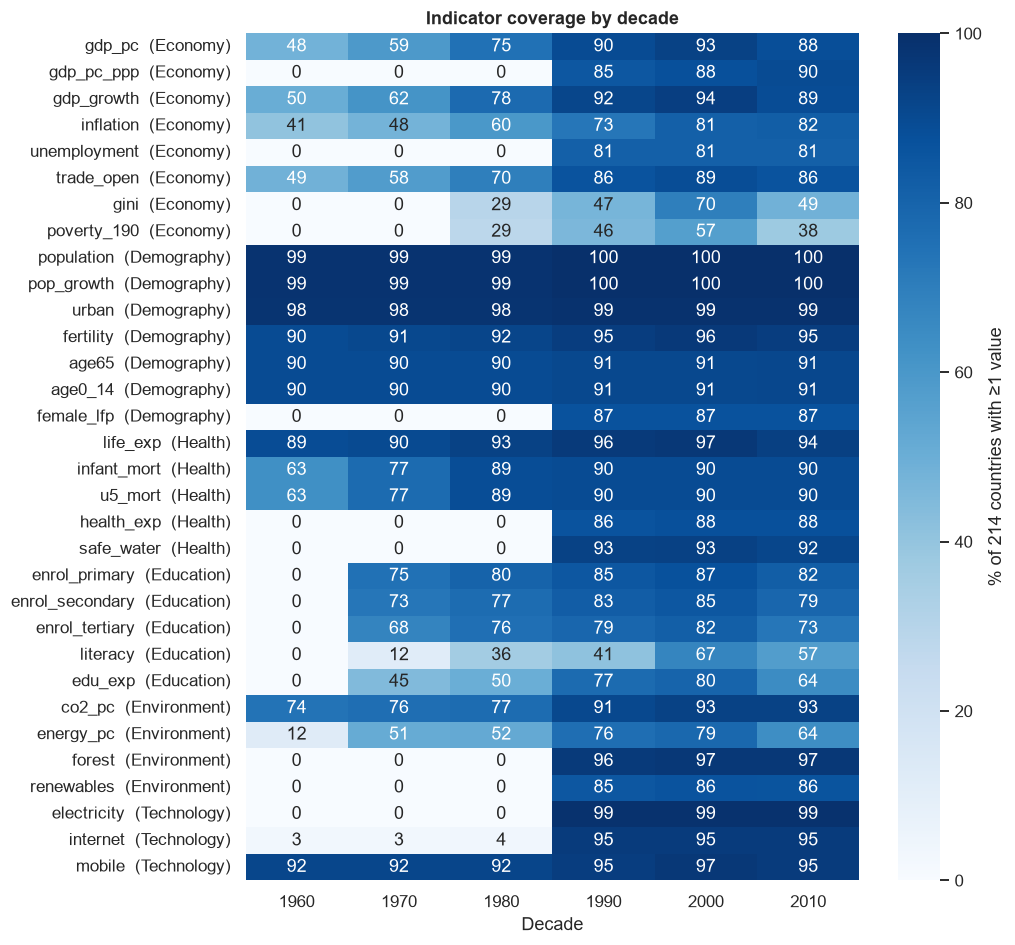

In [7]:
n_countries = len(country_geo)
long["decade"] = (long["Year"] // 10) * 10
coverage = (long.groupby(["indicator", "decade"])["CountryCode"].nunique()
                .unstack(fill_value=0) / n_countries * 100)
coverage = coverage.loc[catalogue.alias]  # keep theme order
coverage.index = [f"{a}  ({THEME[a]})" for a in coverage.index]

fig, ax = plt.subplots(figsize=(9, 10))
sns.heatmap(coverage, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of 214 countries with ≥1 value"}, ax=ax)
ax.set(title="Indicator coverage by decade", xlabel="Decade", ylabel="")
save(fig, "01_coverage_heatmap")
plt.show()

### 4.1 Reshape long → wide

Two analysis-ready views are produced:

* **`panel`**: one row per *(country, year)*, one column per indicator (wide). Used for trends.
* **`snapshot`**: one row per *country*, holding the **most recent value within 2005–2014** for each indicator (and the year it came from). Used for cross-country comparison and modelling.

### 4.2 Missing-value strategy
| Situation | Treatment | Why |
|---|---|---|
| Gaps *inside* a country's time series | linear interpolation within country, max 3 consecutive years, no extrapolation | annual WDI series are smooth; short gaps are mostly reporting gaps |
| Irregular survey indicators in the snapshot | latest value in a 10-year window | Gini/poverty/literacy are surveyed every 3–5 years |
| Remaining gaps for clustering | median within the country's income group | keeps imputation conditional on development level |
| Indicators with < 60 % snapshot coverage | excluded from multivariate models | too much imputation would dominate results |
| Group trends | medians across reporting countries, only shown when ≥ 30 % of countries report | avoids composition artefacts from a few early reporters |

In [8]:
panel = (long.pivot_table(index=["CountryCode", "Year"], columns="indicator", values="Value")
              .reindex(columns=catalogue.alias))
print("wide panel shape (country-years × indicators):", panel.shape)
print(f"cells missing before interpolation: {panel.isna().mean().mean():.1%}")

# Interpolate short internal gaps per country (limit_area='inside' = never extrapolate).
panel = (panel.groupby(level="CountryCode", group_keys=False)
              .apply(lambda g: g.interpolate(method="linear", limit=3, limit_area="inside")))
print(f"cells missing after interpolation:  {panel.isna().mean().mean():.1%}")

panel = panel.join(country_geo[["ShortName", "Region", "Income"]], on="CountryCode")
panel.to_csv(PROCESSED / "wdi_panel_wide.csv")
long.drop(columns="decade").to_csv(PROCESSED / "wdi_long_clean.csv", index=False)
panel.loc[("VNM", slice(2008, 2014)), ["gdp_pc", "life_exp", "fertility", "internet", "co2_pc"]]

wide panel shape (country-years × indicators): (11935, 32)
cells missing before interpolation: 44.9%


cells missing after interpolation:  42.1%


gdp_pc  life_exp  fertility  internet  co2_pc
CountryCode Year                                                
VNM         2008   819.92     75.04       1.86     23.92    1.50
            2009   855.07     75.17       1.84     26.55    1.64
            2010   900.49     75.31       1.82     30.65    1.76
            2011   946.80     75.46       1.79     35.07    1.97
            2012   986.01     75.61       1.77     39.49     NaN
            2013 1,028.63     75.76       1.74     43.90     NaN
            2014 1,077.91       NaN        NaN     48.31     NaN

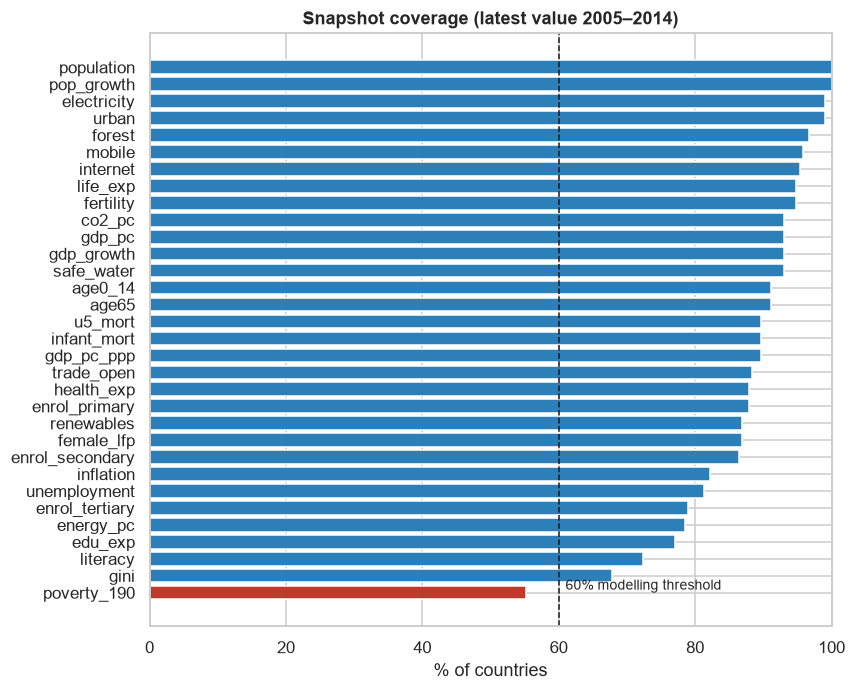

median data year in snapshot: 2014
31 indicators pass the 60% threshold; excluded: ['poverty_190']


In [9]:
# Snapshot: latest non-missing value per country & indicator within 2005-2014.
recent = long[long["Year"].between(2005, 2014)].sort_values("Year")
latest = recent.groupby(["CountryCode", "indicator"]).last()
snapshot = latest["Value"].unstack().reindex(columns=catalogue.alias)
snapshot_year = latest["Year"].unstack().reindex(columns=catalogue.alias)
snapshot = country_geo[["ShortName", "Region", "Income"]].join(snapshot, how="inner")

snap_cov = snapshot[catalogue.alias].notna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#c0392b" if v < 60 else "#2c7fb8" for v in snap_cov]
ax.barh(snap_cov.index, snap_cov.values, color=colors)
ax.axvline(60, ls="--", c="k", lw=1)
ax.set(title="Snapshot coverage (latest value 2005–2014)", xlabel="% of countries", xlim=(0, 100))
ax.text(61, 0, "60% modelling threshold", va="bottom", fontsize=9)
save(fig, "02_snapshot_coverage")
plt.show()

MODEL_VARS = snap_cov[snap_cov >= 60].index.tolist()
print("median data year in snapshot:", int(np.nanmedian(snapshot_year.values)))
print(f"{len(MODEL_VARS)} indicators pass the 60% threshold; excluded:", sorted(set(catalogue.alias) - set(MODEL_VARS)))
snapshot.to_csv(PROCESSED / "wdi_snapshot_2005_2014.csv")

> **Missing-data findings.**
> * Coverage is the main data-quality issue: **45 % of the wide panel cells are empty**. Interpolating short internal gaps fills only ~3 percentage points, which confirms most missingness is *structural* (series that simply did not exist yet) rather than random gaps, and should **not** be imputed.
> * Before 1990 only demography, mortality, GDP, CO₂ and mobile data are broad. Environment (forest, renewables), access (electricity, water), PPP income and labour series start in 1990. So long-run trends use 1960+, and cross-theme comparisons use 1990+ or the snapshot.
> * Survey indicators are sparse: electricity access has values only in survey years and literacy is patchy. In the 2005–2014 snapshot, **31 of 32 indicators clear the 60 % threshold**. Only poverty at $1.90/day (55 %) is excluded from multivariate models.

## 5. Exploratory data analysis

In [10]:
# Descriptive statistics for the snapshot. Skew > 1 flags indicators that need a log transform.
desc = snapshot[catalogue.alias].describe().T
desc["skew"] = snapshot[catalogue.alias].skew()
desc["theme"] = desc.index.map(THEME)
desc[["theme", "count", "mean", "50%", "std", "min", "max", "skew"]]

,theme,count,mean,50%,std,min,max,skew
gdp_pc,Economy,199.00,"13,103.56","4,111.76","20,883.31",152.65,"158,602.52",3.16
gdp_pc_ppp,Economy,192.00,"18,337.17","11,466.99","20,870.21",566.85,"134,182.41",2.53
gdp_growth,Economy,199.00,3.15,3.10,3.53,-24.00,10.30,-2.43
inflation,Economy,176.00,4.19,2.54,7.47,-1.51,62.17,4.90
unemployment,Economy,174.00,8.58,6.90,6.14,0.30,31.00,1.50
trade_open,Economy,189.00,94.68,84.30,53.50,19.12,439.20,2.91
gini,Economy,145.00,38.56,37.35,8.65,16.64,63.38,0.50
poverty_190,Economy,118.00,19.22,7.83,23.10,0.00,81.76,1.10
population,Demography,214.00,"33,819,246.15","6,183,345.00","133,126,383.67","9,893.00","1,364,270,000.00",8.86
pop_growth,Demography,214.00,1.31,1.25,1.24,-4.19,8.09,0.49


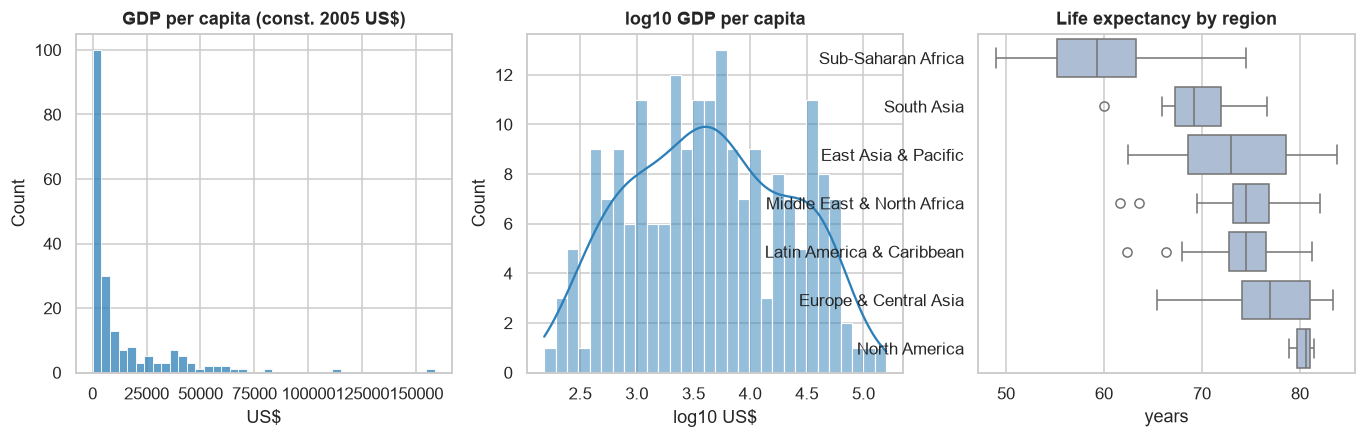

In [11]:
# Income is extremely right-skewed: compare raw vs log scale.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(snapshot["gdp_pc"], bins=40, ax=axes[0], color="#2c7fb8")
axes[0].set(title="GDP per capita (const. 2005 US$)", xlabel="US$")
sns.histplot(np.log10(snapshot["gdp_pc"]), bins=30, kde=True, ax=axes[1], color="#2c7fb8")
axes[1].set(title="log10 GDP per capita", xlabel="log10 US$")
sns.boxplot(data=snapshot, x="life_exp", y="Region", ax=axes[2], color="#a6bddb",
            order=snapshot.groupby("Region")["life_exp"].median().sort_values().index)
axes[2].set(title="Life expectancy by region", xlabel="years", ylabel="")
save(fig, "03_distributions")
plt.show()

In [12]:
# Regional and income-group profiles (medians are robust to outliers such as Qatar or Luxembourg).
KEY = ["gdp_pc", "life_exp", "u5_mort", "fertility", "urban", "enrol_secondary",
       "internet", "co2_pc", "forest"]
by_region = snapshot.groupby("Region")[KEY].median().sort_values("gdp_pc")
by_income = snapshot.groupby("Income", observed=True)[KEY].median()
display(by_income.style.format("{:,.1f}").background_gradient(cmap="RdYlGn", axis=0)
        .set_caption("Median snapshot by income group"))
display(by_region.style.format("{:,.1f}").background_gradient(cmap="RdYlGn", axis=0)
        .set_caption("Median snapshot by region"))

,gdp_pc,life_exp,u5_mort,fertility,urban,enrol_secondary,internet,co2_pc,forest
Income,,,,,,,,,
Low income,432.6,59.3,80.8,4.9,31.9,37.9,5.4,0.1,23.4
Lower middle income,"1,241.4",68.1,40.0,3.3,43.2,68.9,23.0,0.8,29.3
Upper middle income,"4,665.9",73.9,16.3,2.2,64.3,91.8,44.4,3.2,33.5
High income,"26,532.6",79.8,4.5,1.8,82.4,102.8,76.8,7.4,33.0


,gdp_pc,life_exp,u5_mort,fertility,urban,enrol_secondary,internet,co2_pc,forest
Region,,,,,,,,,
Sub-Saharan Africa,665.1,59.3,72.6,4.8,39.7,42.2,10.6,0.3,26.2
South Asia,"1,023.8",69.2,38.5,2.3,32.9,67.0,16.7,0.7,17.3
East Asia & Pacific,"2,701.7",72.9,23.5,2.3,57.4,87.3,39.7,2.2,47.2
Middle East & North Africa,"3,953.4",74.5,14.6,2.8,77.3,88.4,53.7,4.7,1.1
Latin America & Caribbean,"5,658.6",74.5,17.0,2.2,67.2,91.2,49.6,2.4,44.1
Europe & Central Asia,"15,797.5",77.0,4.6,1.6,67.2,101.1,69.9,6.3,30.8
North America,"46,405.2",80.6,5.8,1.6,81.7,94.0,87.4,14.1,33.8


> **EDA findings.**
> * **Income is extremely skewed** (skew 3.2): median GDP per capita is US$4,100 but the mean is US$13,100, and the range runs from US$153 (Burundi) to US$158,600 (Monaco). It is close to log-normal, so all income models below use **log GDP**.
> * Other skewed variables are population (8.9), inflation (4.9), trade openness (2.9) and CO₂ (2.8). Bounded shares (urban, water, literacy) are left-skewed because many countries sit near 100 %.
> * **Life expectancy spans 35 years** across countries (48.9 in Swaziland to 83.8 in Hong Kong/Japan). Sub-Saharan Africa sits clearly below every other region.

*Reading the tables:* colours run green (high) to red (low) per column; for mortality, fertility and CO₂, "high" is not "good", so read each column on its own terms.

## 6. Trend analysis by theme (1960–2014)

For each theme we plot the **median across countries in each World Bank income group**. Medians are used so that a few very large or very rich countries do not dominate, and a year is only plotted when at least 30 % of the group's countries report (coverage rule from §4.2).

In [13]:
def group_trend(var, by="Income", min_share=0.3):
    # Median of var per (group, year), masked where too few countries report.
    g = panel.groupby([by, "Year"], observed=True)[var]
    med, n = g.median(), g.count()
    size = country_geo.groupby(by, observed=True).size()
    share = n / np.asarray(n.index.get_level_values(0).map(size), dtype=float)
    return med.where(share >= min_share).unstack(0)

INCOME_COLORS = dict(zip(INCOME_ORDER, ["#d7301f", "#fc8d59", "#74add1", "#4575b4"]))

def theme_grid(vars_titles, fname, by="Income", ncols=3, logy=()):
    n = len(vars_titles)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)
    for ax, (var, title) in zip(axes.flat, vars_titles):
        t = group_trend(var, by)
        for col in t.columns:
            ax.plot(t.index, t[col], label=col, lw=2, color=INCOME_COLORS.get(col))
        ax.set_title(title)
        if var in logy:
            ax.set_yscale("log")
    for ax in axes.flat[n:]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=8, loc="best")
    fig.tight_layout()
    save(fig, fname)
    plt.show()

### 6.1 Economy

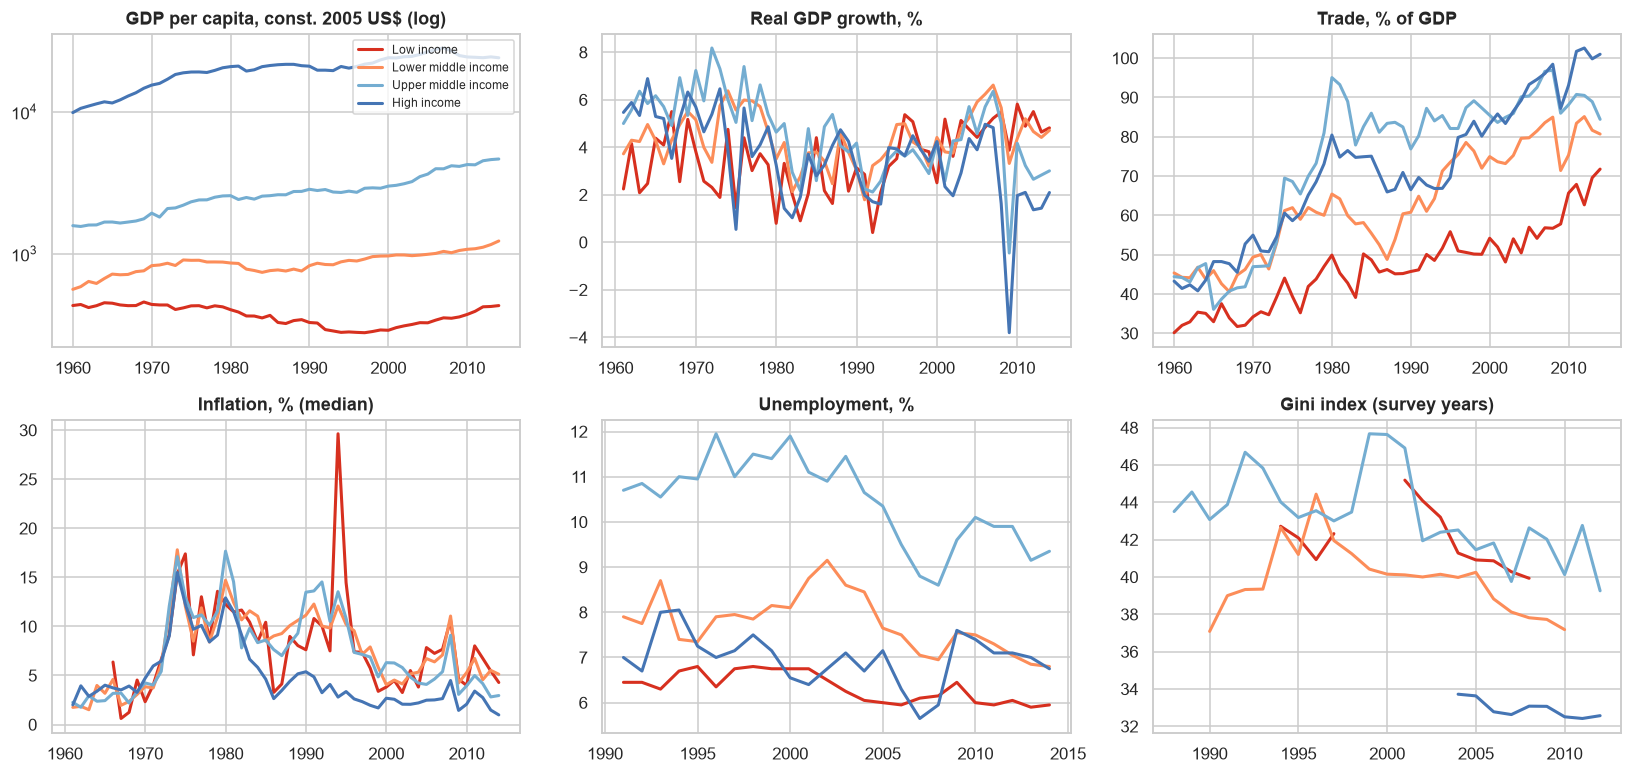

CAGR of median GDP per capita 1990→2014, %/yr:
Income
Low income            1.15
Lower middle income   1.68
Upper middle income   2.07
High income           0.57


In [14]:
theme_grid([("gdp_pc", "GDP per capita, const. 2005 US$ (log)"),
            ("gdp_growth", "Real GDP growth, %"),
            ("trade_open", "Trade, % of GDP"),
            ("inflation", "Inflation, % (median)"),
            ("unemployment", "Unemployment, %"),
            ("gini", "Gini index (survey years)")],
           "04_trend_economy", logy=("gdp_pc",))

# Compound annual growth of median GDP per capita 1990-2014 by income group.
t = group_trend("gdp_pc")
cagr = ((t.loc[2014] / t.loc[1990]) ** (1 / 24) - 1) * 100
print("CAGR of median GDP per capita 1990→2014, %/yr:"); print(cagr.round(2).to_string())

> **Economy.** Income levels diverged in absolute terms. Since 1990, median GDP per capita grew **2.1 %/yr in upper-middle-income countries and 1.7 % in lower-middle**, versus only **0.6 % in high-income** countries, so middle-income economies are catching up in relative terms. Low-income countries were stagnant or shrinking from 1970 to the mid-1990s and have only recovered since 2000 (1.2 %/yr over 1990–2014). The 2009 global financial crisis is the only year in which median high-income growth turned clearly negative (around −4 %). The world became more open: median trade rose from about 40 % to 80–100 % of GDP. Inflation peaked in the 1970s oil shocks and has been subdued since the late 1990s. Within-country inequality (Gini) is much lower in rich countries (~33) than in middle-income ones (~40).

### 6.2 Demography

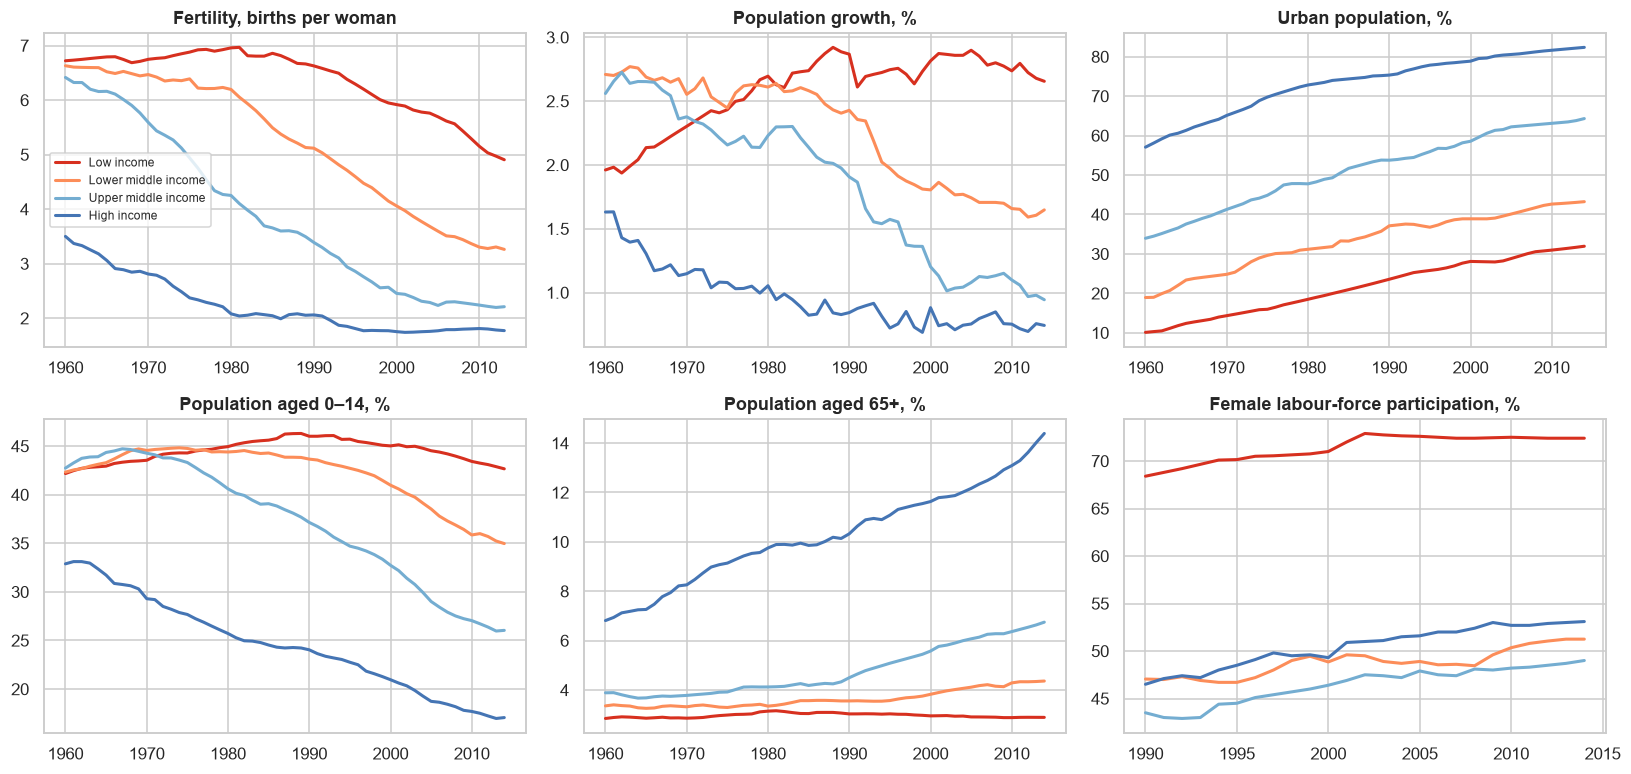

World population: 3.03 bn (1960) → 7.26 bn (2014)


In [15]:
theme_grid([("fertility", "Fertility, births per woman"),
            ("pop_growth", "Population growth, %"),
            ("urban", "Urban population, %"),
            ("age0_14", "Population aged 0–14, %"),
            ("age65", "Population aged 65+, %"),
            ("female_lfp", "Female labour-force participation, %")],
           "05_trend_demography")

# World population from the official aggregate (not a sum of the panel, which has gaps).
world_pop = agg_long.query("CountryCode=='WLD' and indicator=='population'").set_index("Year")["Value"]
print(f"World population: {world_pop.loc[1960]/1e9:.2f} bn (1960) → {world_pop.loc[2014]/1e9:.2f} bn (2014)")

> **Demography.** World population rose from **3.0 bn (1960) to 7.3 bn (2014)**. The demographic transition is visible in every income group: fertility fell almost everywhere, from 6+ births per woman to about 2 in middle-income countries. **Low-income countries are the exception**: fertility is still near 5, so their populations are young (over 40 % under 15) and growing fast. High-income societies are ageing: the median 65+ share is already 14 % (vs 3 % in low-income countries) and rising. Urbanisation rose steadily in all groups.

### 6.3 Health

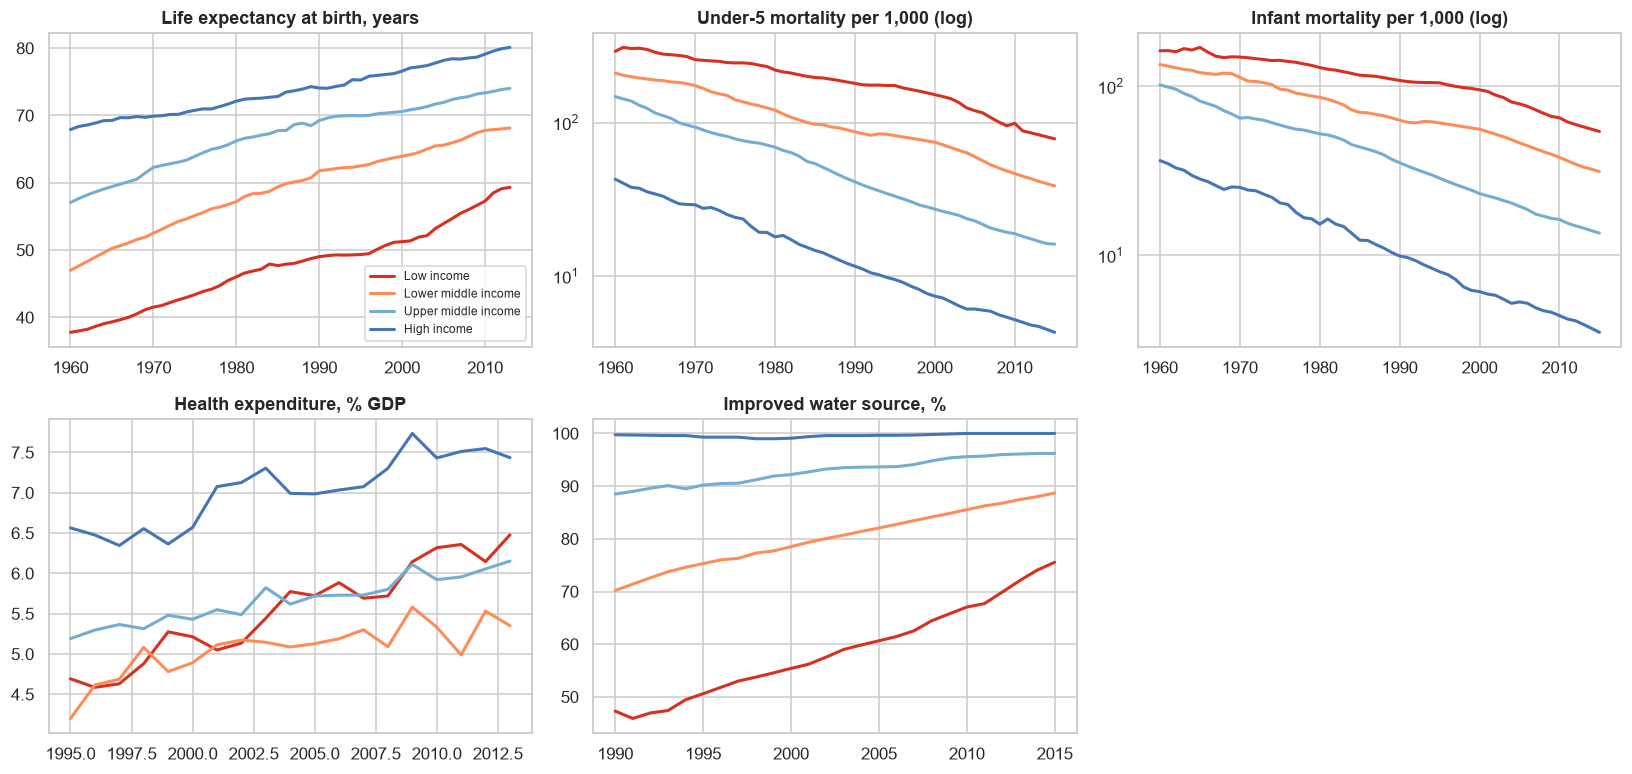

Life-expectancy gap high vs low income: 30.1 yrs (1960) → 20.8 yrs (2013)


In [16]:
theme_grid([("life_exp", "Life expectancy at birth, years"),
            ("u5_mort", "Under-5 mortality per 1,000 (log)"),
            ("infant_mort", "Infant mortality per 1,000 (log)"),
            ("health_exp", "Health expenditure, % GDP"),
            ("safe_water", "Improved water source, %")],
           "06_trend_health", logy=("u5_mort", "infant_mort"))

le = group_trend("life_exp")
gap = le["High income"] - le["Low income"]
print(f"Life-expectancy gap high vs low income: {gap.loc[1960]:.1f} yrs (1960) → {gap.dropna().iloc[-1]:.1f} yrs ({gap.dropna().index[-1]})")

> **Health.** This is the strongest success story in the data. The life-expectancy gap between high- and low-income countries **narrowed from 30.1 years (1960) to 20.8 years (2013)**. Under-5 mortality fell by roughly an order of magnitude in middle-income countries (note the log scale). The dip in low-income life expectancy in the 1990s reflects the HIV/AIDS epidemic in Southern Africa, which also explains several outliers in §8.2.

### 6.4 Education

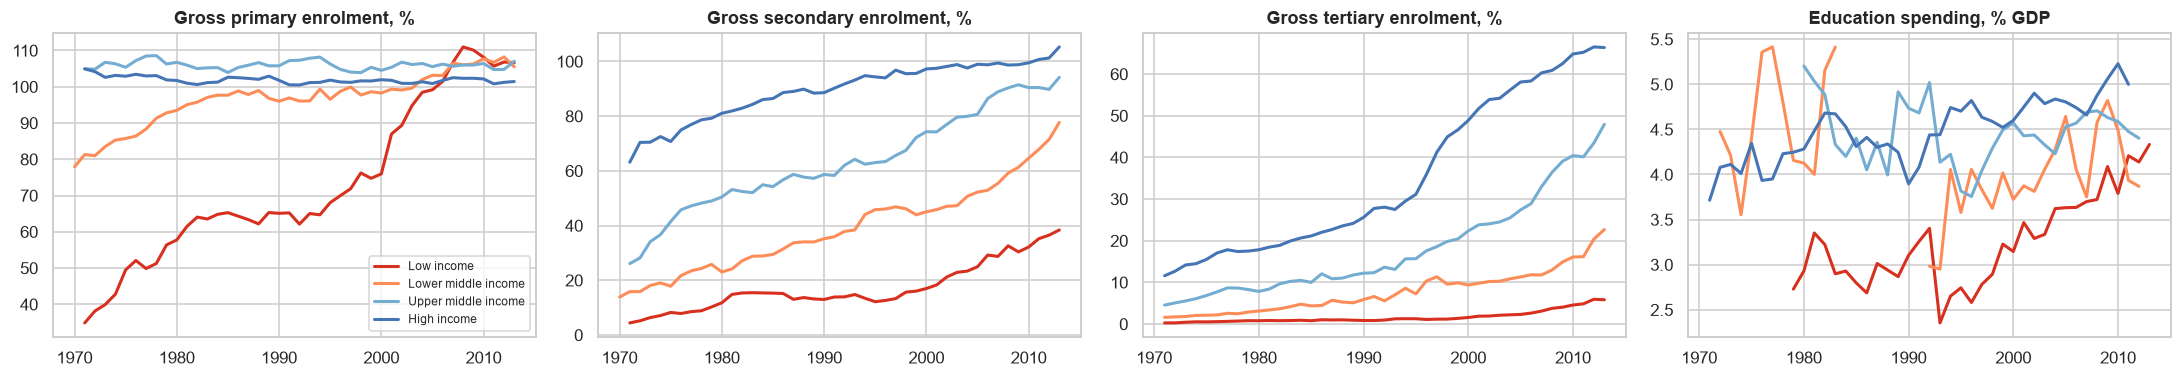

In [17]:
theme_grid([("enrol_primary", "Gross primary enrolment, %"),
            ("enrol_secondary", "Gross secondary enrolment, %"),
            ("enrol_tertiary", "Gross tertiary enrolment, %"),
            ("edu_exp", "Education spending, % GDP")],
           "07_trend_education", ncols=4)

> **Education.** Primary enrolment converged to universal levels (around 100 % gross) in all groups by the 2000s. The remaining gaps are at **secondary and especially tertiary level**, where high-income countries are far ahead (median tertiary enrolment 63 % versus 5 % in low-income countries). Public education spending clusters around 4.1–4.8 % of GDP in every group, so the gaps reflect the size of GDP more than effort.

### 6.5 Environment and energy

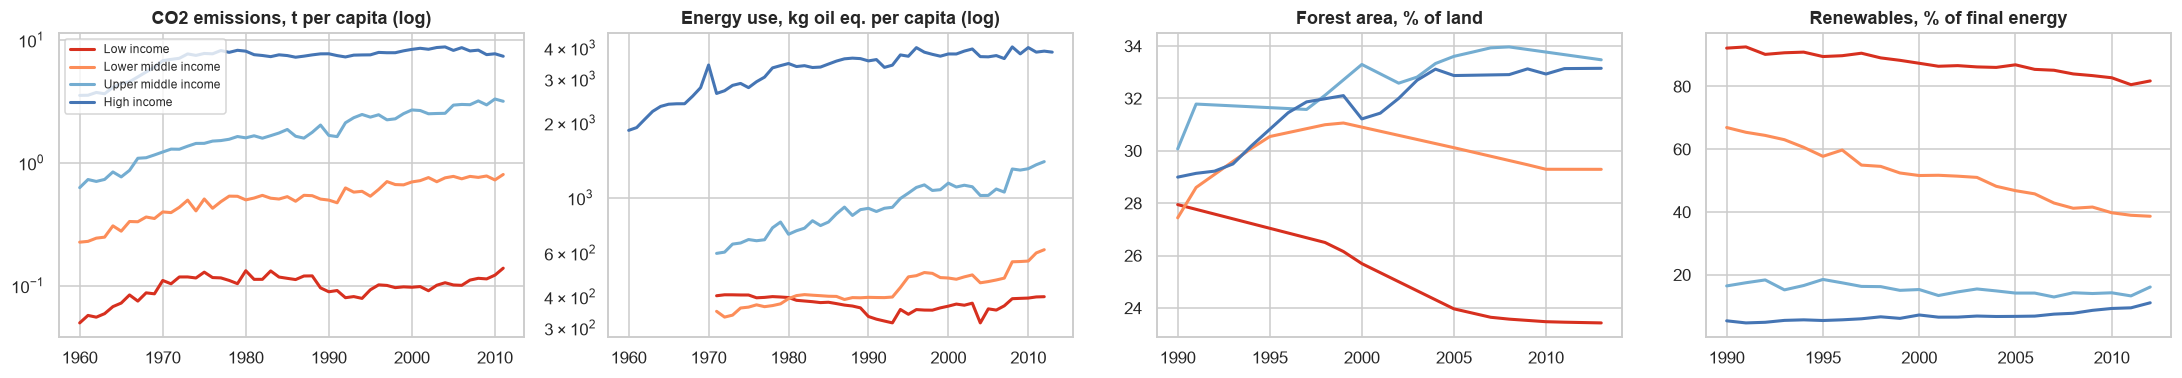

indicator  co2_pc  forest  renewables
Year                                 
1990         4.20   31.75       16.62
2000         4.05   31.19       17.42
2010         4.84   30.89       17.78
2011         4.94   30.81       17.87
2012          NaN   30.79       18.12


In [18]:
theme_grid([("co2_pc", "CO2 emissions, t per capita (log)"),
            ("energy_pc", "Energy use, kg oil eq. per capita (log)"),
            ("forest", "Forest area, % of land"),
            ("renewables", "Renewables, % of final energy")],
           "08_trend_environment", ncols=4, logy=("co2_pc", "energy_pc"))

# Global totals from the WLD aggregate where available.
wld = agg_long.query("CountryCode=='WLD'").pivot_table(index="Year", columns="indicator", values="Value")
print(wld[["co2_pc", "forest", "renewables"]].loc[[1990, 2000, 2010, 2011, 2012]].round(2))

> **Environment.** Emissions follow income. World CO₂ per capita was roughly flat around 4.1–4.2 t in 1990–2000, then **rose to 4.9 t by 2011**, driven by fast-growing middle-income economies. Median high-income per-capita emissions more than doubled in the 1960s–70s, plateaued around 8 t from the late 1970s, and slipped to 7.4 t by 2011. World forest cover fell steadily from **31.8 % to 30.8 % of land** (1990–2012). The renewable share of world final energy rose only slightly (16.6 % → 18.1 %). It is highest in low-income countries, where it means traditional biomass, not modern renewables.

### 6.6 Technology and infrastructure

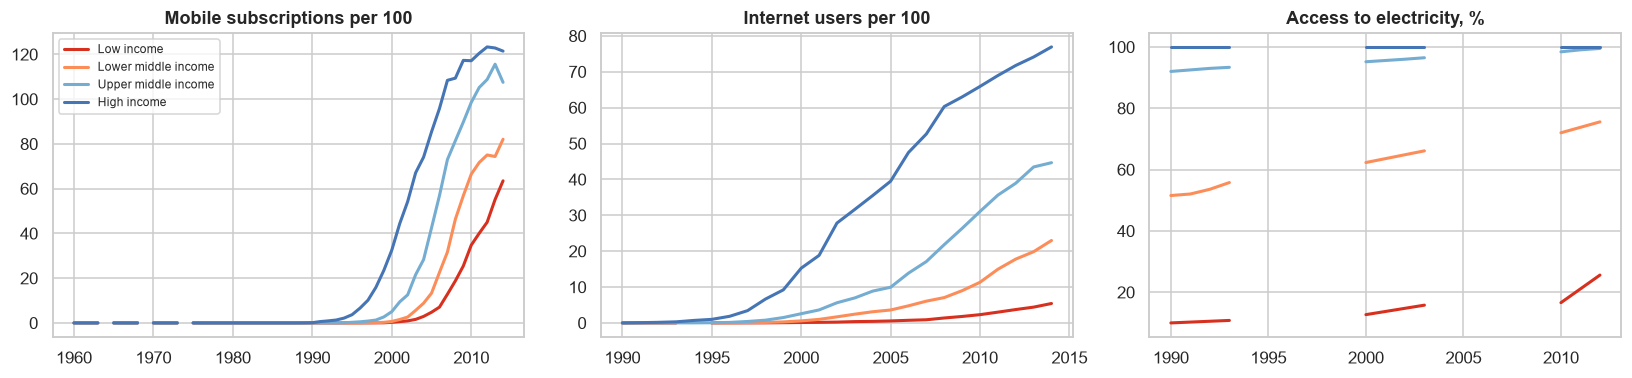

In [19]:
theme_grid([("mobile", "Mobile subscriptions per 100"),
            ("internet", "Internet users per 100"),
            ("electricity", "Access to electricity, %")],
           "09_trend_technology")

> **Technology.** Mobile phones are the fastest diffusion in the dataset: from near zero in 2000 to more than one subscription per person in upper-middle- and high-income countries (medians 108 and 121 per 100), 80 in lower-middle and about 64 per 100 even in low-income countries. They leapfrogged fixed infrastructure. Internet use lags mobile by about a decade and is much more unequal. Electricity access is near universal outside low-income countries.

### 6.7 Regional view: speed of change
The income-group lens hides how differently regions moved. The chart below shows median life expectancy and fertility by region: East Asia and the Middle East went through the demographic transition fastest, Sub-Saharan Africa slowest.

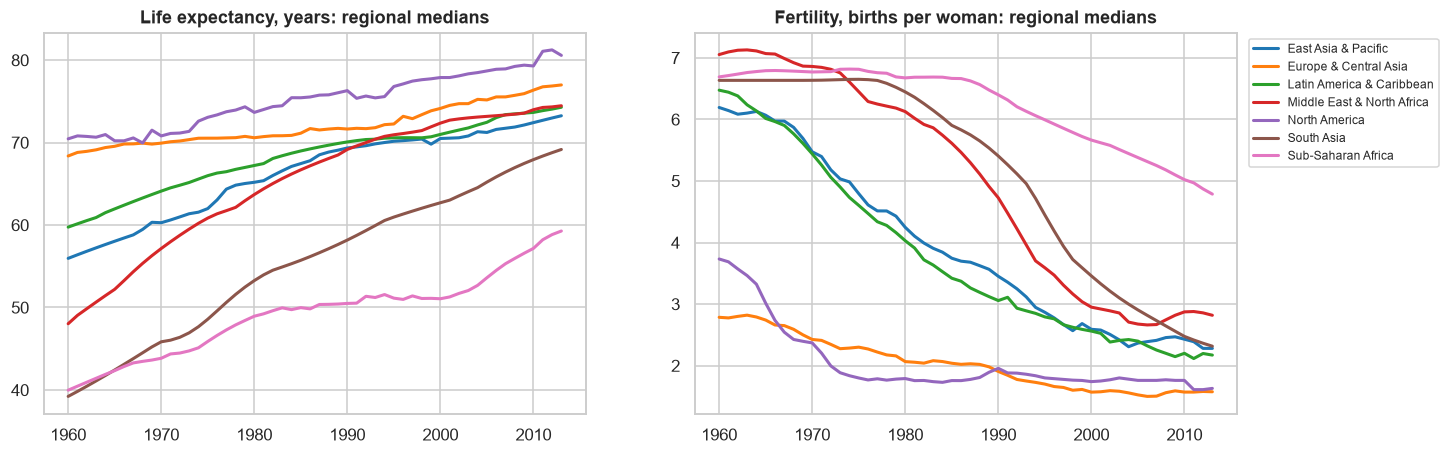

,life_exp_1960,life_exp_2013,fertility_1960,fertility_2013,life_exp_gain,fertility_drop_%
Region,,,,,,
South Asia,39.20,69.20,6.60,2.30,29.90,65.10
Middle East & North Africa,48.00,74.50,7.10,2.80,26.40,60.10
Sub-Saharan Africa,40.00,59.30,6.70,4.80,19.30,28.50
East Asia & Pacific,56.00,73.30,6.20,2.30,17.30,63.20
Latin America & Caribbean,59.70,74.30,6.50,2.20,14.50,66.50
North America,70.50,80.60,3.70,1.60,10.10,56.30
Europe & Central Asia,68.40,77.00,2.80,1.60,8.60,43.40


In [20]:
REGION_COLORS = dict(zip(sorted(country_geo["Region"].unique()), sns.color_palette("tab10", 7)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (var, title) in zip(axes, [("life_exp", "Life expectancy, years"), ("fertility", "Fertility, births per woman")]):
    t = group_trend(var, by="Region")
    for col in t.columns:
        ax.plot(t.index, t[col], label=col, lw=2, color=REGION_COLORS[col])
    ax.set_title(f"{title}: regional medians")
axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "10_trend_regions")
plt.show()

change = pd.DataFrame({
    "life_exp_1960": group_trend("life_exp", "Region").loc[1960],
    "life_exp_2013": group_trend("life_exp", "Region").loc[2013],
    "fertility_1960": group_trend("fertility", "Region").loc[1960],
    "fertility_2013": group_trend("fertility", "Region").loc[2013]})
change["life_exp_gain"] = change.life_exp_2013 - change.life_exp_1960
change["fertility_drop_%"] = (1 - change.fertility_2013 / change.fertility_1960) * 100
change.sort_values("life_exp_gain", ascending=False).round(1)

> **Regional speed of change.** South Asia gained the most life expectancy (+29.9 years, 39 → 69) and MENA cut fertility from 7.1 to 2.8. Sub-Saharan Africa gained 19 years, but its fertility fell only 28 %, versus 60–67 % in South Asia, MENA, East Asia and Latin America. That is the key reason Africa's population momentum continues.

## 7. Cross-country comparison

### 7.1 Leaders and laggards (latest snapshot)

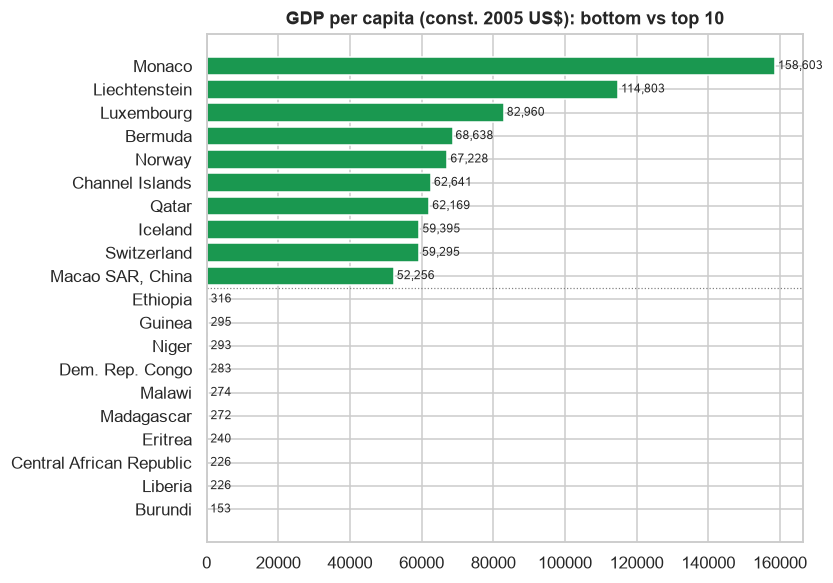

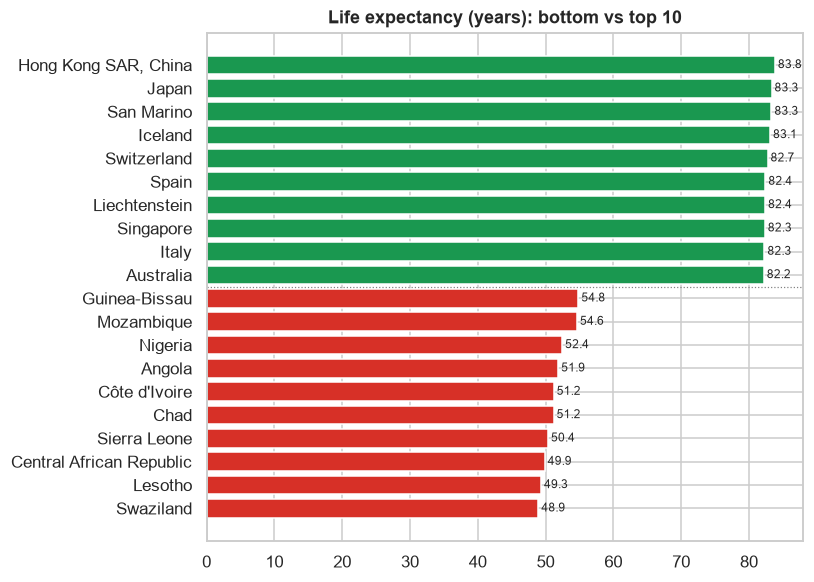

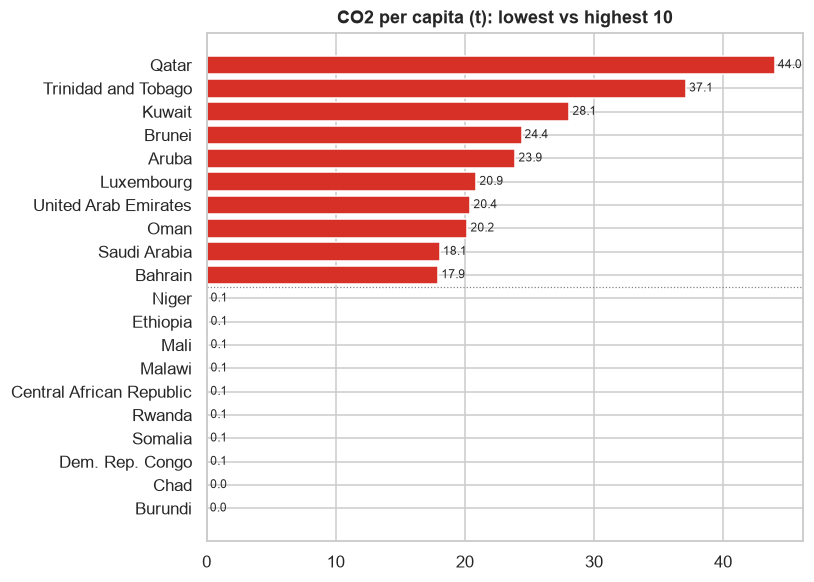

In [21]:
def top_bottom(var, n=10, title="", fmt="{:,.0f}", fname=None, higher_is_better=True):
    s = snapshot.set_index("ShortName")[var].dropna().sort_values()
    sel = pd.concat([s.head(n), s.tail(n)])
    good, bad = "#1a9850", "#d73027"
    colors = [bad] * n + [good] * n if higher_is_better else [good] * n + [bad] * n
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(sel.index, sel.values, color=colors)
    ax.axhline(n - 0.5, color="grey", lw=0.8, ls=":")
    for i, v in enumerate(sel.values):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8)
    ax.set_title(title)
    if fname:
        save(fig, fname)
    plt.show()

top_bottom("gdp_pc", title="GDP per capita (const. 2005 US$): bottom vs top 10", fname="11_rank_gdp")
top_bottom("life_exp", title="Life expectancy (years): bottom vs top 10", fmt="{:.1f}", fname="12_rank_life")
top_bottom("co2_pc", title="CO2 per capita (t): lowest vs highest 10", fmt="{:.1f}",
           fname="13_rank_co2", higher_is_better=False)

> **Rankings.** The top of the income table is dominated by small financial centres and resource economies (Monaco, Liechtenstein, Luxembourg, Bermuda, Norway, Channel Islands). **All 10 poorest countries are in Sub-Saharan Africa** (Burundi, Liberia, Central African Republic, Eritrea, ...), and so are the 10 lowest life expectancies. The highest per-capita CO₂ emitters are small oil and gas producers (Qatar 44 t, Trinidad and Tobago 37 t, Kuwait 28 t), more than 1,000× the lowest emitters (Burundi, Chad: ~0.02–0.05 t). This is why per-capita and total views of emissions tell very different stories.

### 7.2 How unequal is development?
We measure dispersion across countries with the **Gini coefficient of country values** (0 = all countries equal, 1 = maximal inequality) and the **ratio of the 90th to the 10th percentile country**. Comparing 1990 with the latest year shows whether countries are converging on each outcome.

In [22]:
def gini(x):
    x = np.sort(np.asarray(x.dropna()))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

rows = []
for var in ["gdp_pc", "life_exp", "u5_mort", "fertility", "enrol_secondary", "co2_pc", "electricity", "mobile"]:
    for yr in (1990, 2011):  # 2011 = last year with CO2 data
        x = panel.xs(yr, level="Year")[var].dropna()
        rows.append({"indicator": var, "year": yr, "n": len(x), "gini_across_countries": gini(x),
                     # p90/p10 is undefined when the 10th-percentile country is ~0 (e.g. mobiles in 1990).
                     "p90/p10": x.quantile(.9) / x.quantile(.1) if x.quantile(.1) > 1e-3 * x.quantile(.9) else np.nan})
ineq = pd.DataFrame(rows).pivot(index="indicator", columns="year", values=["gini_across_countries", "p90/p10"])
ineq

gini_across_countries      p90/p10      
year                             1990 2011    1990  2011
indicator                                               
co2_pc                           0.66 0.59  109.19 63.88
electricity                      0.26 0.20    8.25  4.34
enrol_secondary                  0.32 0.18    7.38  2.82
fertility                        0.27 0.27    3.76  3.55
gdp_pc                           0.70 0.67   76.88 81.02
life_exp                         0.08 0.07    1.54  1.41
mobile                           0.90 0.25     NaN  3.98
u5_mort                          0.50 0.53   18.92 23.01

> **Inequality between countries.** For *basic outcomes* countries are converging. The cross-country Gini fell for secondary enrolment (0.32 → 0.18), electricity access (0.26 → 0.20), mobile phones (0.90 → 0.25) and CO₂ per capita (0.66 → 0.59). For *income*, there is essentially no convergence: the Gini stayed at about 0.67–0.70, and the richest-to-poorest decile ratio even rose (77× → 81×). Under-5 mortality became slightly *more* unequal in relative terms (Gini 0.50 → 0.53). Rich and middle-income countries pushed child mortality close to its floor faster than the poorest countries did, even though the poorest also improved a lot in absolute terms.

### 7.3 Income convergence (β-convergence)
Do poorer countries grow faster and catch up? We regress average annual growth of GDP per capita (1990–2014) on log initial income (1990). A negative, significant slope would indicate **absolute convergence**.

n=157  slope=-0.202 pp per log-point  r=-0.16  p=0.050


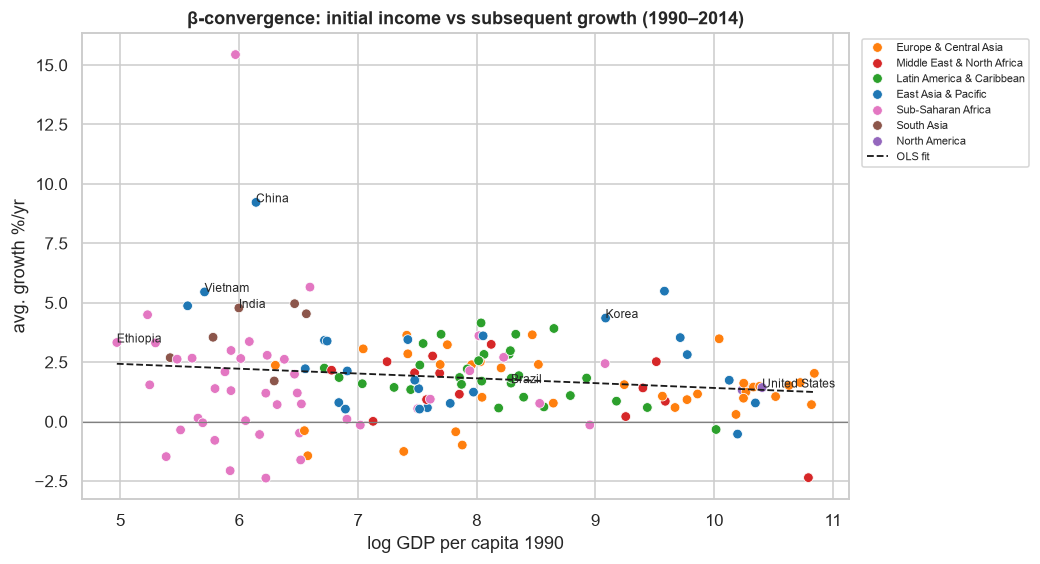

,ShortName,Region,growth_pa
CountryCode,,,
GNQ,Equatorial Guinea,Sub-Saharan Africa,15.44
CHN,China,East Asia & Pacific,9.22
CPV,Cabo Verde,Sub-Saharan Africa,5.66
MAC,"Macao SAR, China",East Asia & Pacific,5.49
VNM,Vietnam,East Asia & Pacific,5.45
BTN,Bhutan,South Asia,4.96
LAO,Lao PDR,East Asia & Pacific,4.87
IND,India,South Asia,4.78


In [23]:
g = panel["gdp_pc"].unstack("Year")[[1990, 2014]].dropna()
conv = pd.DataFrame({"log_gdp_1990": np.log(g[1990]),
                     "growth_pa": ((g[2014] / g[1990]) ** (1 / 24) - 1) * 100}).join(country_geo)
res = stats.linregress(conv.log_gdp_1990, conv.growth_pa)
print(f"n={len(conv)}  slope={res.slope:.3f} pp per log-point  r={res.rvalue:.2f}  p={res.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=conv, x="log_gdp_1990", y="growth_pa", hue="Region", palette=REGION_COLORS, ax=ax, s=40)
xs = np.linspace(conv.log_gdp_1990.min(), conv.log_gdp_1990.max(), 50)
ax.plot(xs, res.intercept + res.slope * xs, "k--", lw=1.2, label="OLS fit")
for code_ in ["CHN", "VNM", "IND", "USA", "COD", "KOR", "ETH", "BRA"]:
    if code_ in conv.index:
        ax.annotate(country_geo.loc[code_, "ShortName"], conv.loc[code_, ["log_gdp_1990", "growth_pa"]], fontsize=8)
ax.axhline(0, c="grey", lw=0.8)
ax.set(title="β-convergence: initial income vs subsequent growth (1990–2014)",
       xlabel="log GDP per capita 1990", ylabel="avg. growth %/yr")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "14_convergence")
plt.show()

conv.nlargest(8, "growth_pa")[["ShortName", "Region", "growth_pa"]]

> **Convergence result.** The slope is negative (−0.20 pp of growth per log-point of initial income) but **weak and only borderline significant** (r = −0.16, p = 0.05, n = 157). So there is at best faint absolute convergence over 1990–2014. Catch-up is concentrated in a few fast growers: China (9.2 %/yr), Vietnam (5.5 %), Lao PDR, India, Bhutan, Cabo Verde, plus oil-driven Equatorial Guinea. Many poor countries, especially in Sub-Saharan Africa, did not grow faster than rich ones. Growth depends on conditions (institutions, investment, human capital), not on starting poor.

### 7.4 Case study: Vietnam and regional peers
Vietnam is a widely cited development success after the 1986 *Đổi Mới* reforms. We compare it with China, Thailand, Indonesia, the Philippines, Malaysia and India on six indicators spanning all themes.

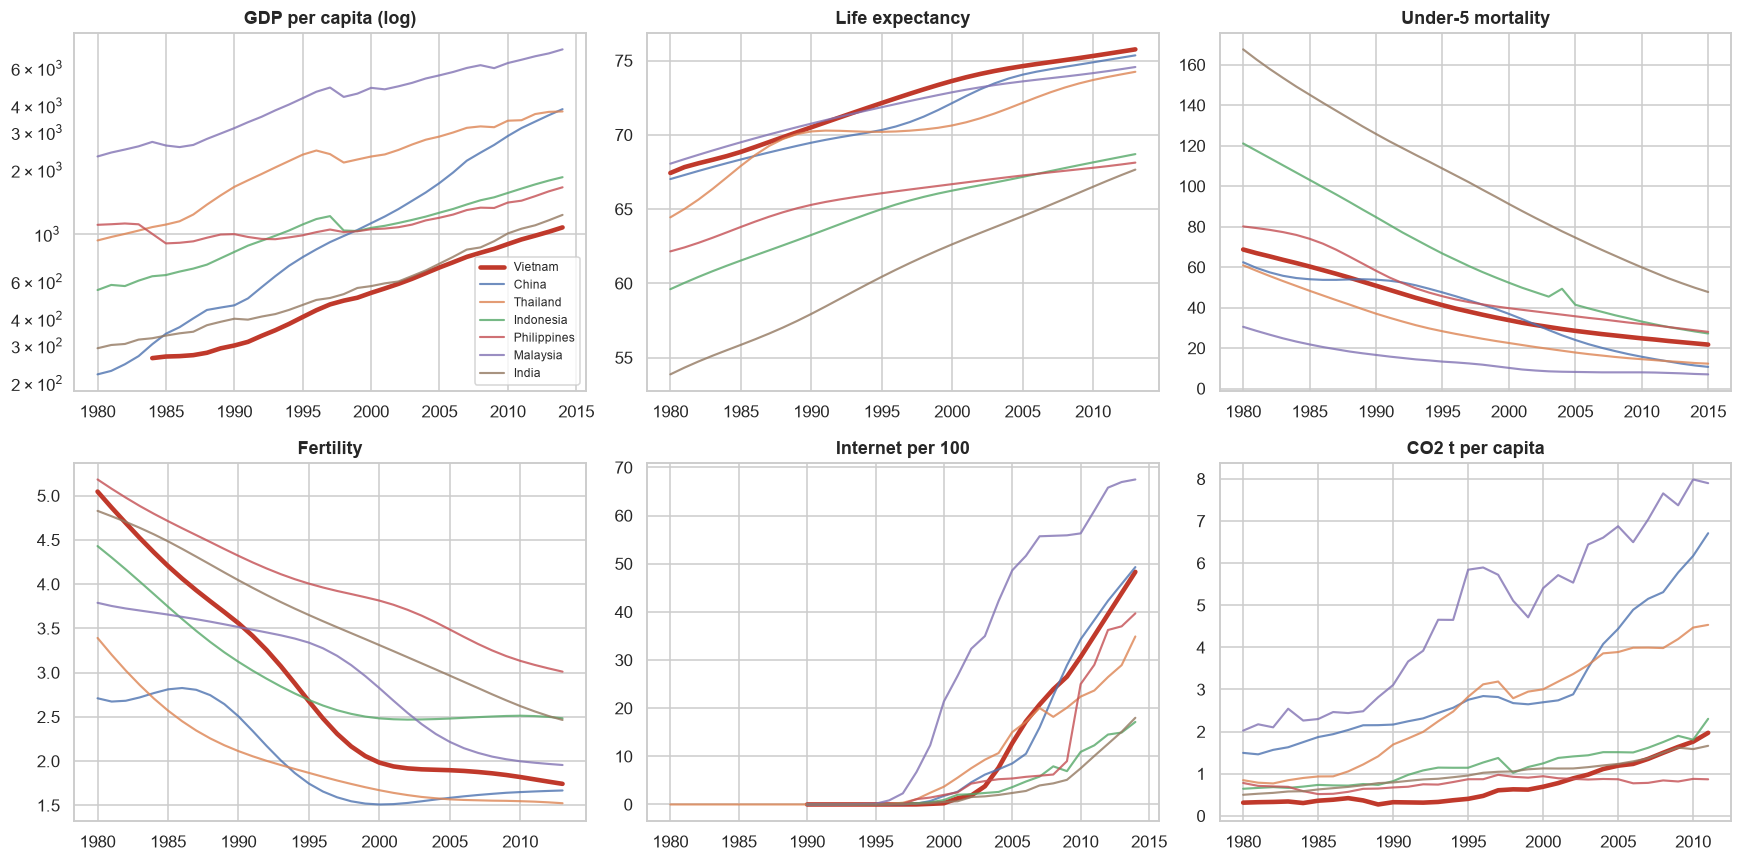

Vietnam GDP pc: 263 US$ (1984) → 1078 US$ (2014), x4.1


,gdp_pc,life_exp,u5_mort,fertility,enrol_secondary,internet,co2_pc,forest
CountryCode,,,,,,,,
Vietnam,"1,077.91",75.76,22.30,1.74,NaN,48.31,1.97,46.81
China,"3,862.92",75.35,11.40,1.67,92.41,49.30,6.71,21.86
Thailand,"3,768.79",74.25,12.60,1.52,85.91,34.89,4.53,31.98
Indonesia,"1,853.81",68.70,28.20,2.48,83.05,17.14,2.30,50.99
Philippines,"1,662.07",68.13,28.80,3.01,85.37,39.69,0.87,25.35
Malaysia,"7,365.24",74.57,7.20,1.96,70.80,67.50,7.90,67.47
India,"1,233.95",67.66,49.80,2.46,71.47,18.00,1.66,23.65


In [24]:
PEERS = {"VNM": "Vietnam", "CHN": "China", "THA": "Thailand", "IDN": "Indonesia",
         "PHL": "Philippines", "MYS": "Malaysia", "IND": "India"}
vars_ = [("gdp_pc", "GDP per capita (log)"), ("life_exp", "Life expectancy"), ("u5_mort", "Under-5 mortality"),
         ("fertility", "Fertility"), ("internet", "Internet per 100"), ("co2_pc", "CO2 t per capita")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (var, title) in zip(axes.flat, vars_):
    for c, name in PEERS.items():
        s = panel.loc[c, var].dropna()
        s = s[s.index >= 1980]
        ax.plot(s.index, s.values, lw=3 if c == "VNM" else 1.4, label=name,
                color="#c0392b" if c == "VNM" else None, alpha=1 if c == "VNM" else .8)
    ax.set_title(title)
    if var == "gdp_pc":
        ax.set_yscale("log")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
save(fig, "15_vietnam_peers")
plt.show()

vn = panel.loc["VNM"]
first = vn["gdp_pc"].first_valid_index()
print(f"Vietnam GDP pc: {vn.loc[first,'gdp_pc']:.0f} US$ ({first}) → {vn.loc[2014,'gdp_pc']:.0f} US$ (2014), "
      f"x{vn.loc[2014,'gdp_pc']/vn.loc[first,'gdp_pc']:.1f}")
peer_tbl = snapshot.loc[list(PEERS), ["gdp_pc", "life_exp", "u5_mort", "fertility", "enrol_secondary",
                                      "internet", "co2_pc", "forest"]].rename(index=PEERS)
peer_tbl

> **Vietnam vs peers.** Vietnam's real GDP per capita rose **4.1× from 1984 to 2014** (US$263 → US$1,078 at constant 2005 prices), among the five fastest growth rates in the world since 1990. Its social outcomes are far ahead of its income. **Life expectancy (75.8) matches China and Thailand, which are ~3.5× richer**, and beats Indonesia, the Philippines and India by 7–8 years. Fertility (1.74) is already below replacement, like China and Thailand. Internet use (48 per 100) is level with China. Per-capita CO₂ (2.0 t) is still low but rising fast. Vietnam retains high forest cover (47 %) thanks to reforestation programmes. The main gaps versus richer peers are income level and child mortality (22 per 1,000 vs 7–13 in Malaysia, China, Thailand).

## 8. Evaluation: relationships, models and clusters

### 8.1 Correlation structure
Spearman rank correlation (robust to skew and outliers) between the indicators that passed the coverage threshold.

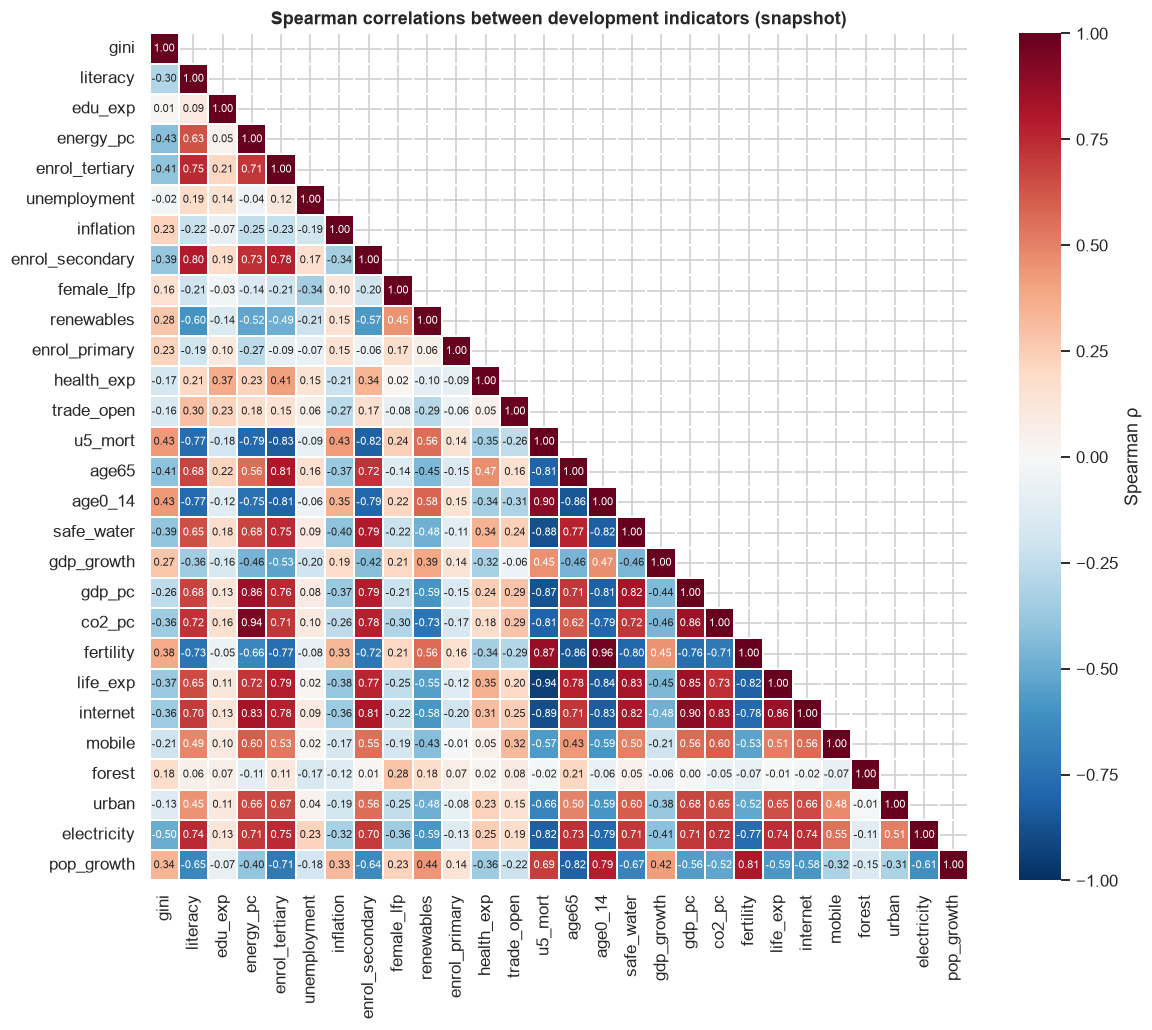

Strongest correlations with GDP per capita:
internet           0.90
u5_mort           -0.87
co2_pc             0.86
energy_pc          0.86
life_exp           0.85
safe_water         0.82
age0_14           -0.81
enrol_secondary    0.79
fertility         -0.76
enrol_tertiary     0.76


In [25]:
corr_vars = [v for v in MODEL_VARS if v not in ("population", "gdp_pc_ppp", "infant_mort")]  # drop size & near-duplicates
corr = snapshot[corr_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), 1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.3, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Spearman correlations between development indicators (snapshot)")
save(fig, "16_correlation")
plt.show()

pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), -1)).stack().rename("rho")
print("Strongest correlations with GDP per capita:")
print(corr["gdp_pc"].drop("gdp_pc").sort_values(key=abs, ascending=False).head(10).round(2).to_string())

> **Correlation findings.** Development is strongly *one-dimensional*. GDP per capita correlates at |ρ| ≥ 0.75 with internet use (0.90), under-5 mortality (−0.87), CO₂ and energy use (0.86), life expectancy (0.85), safe water (0.82), the young-age share (−0.81), secondary enrolment (0.79) and fertility (−0.76). Correlation is not causation: income both enables and results from health and education. Notably, **CO₂ is as tightly tied to income as health is**, which shows the environmental cost of the current growth model. Weakly related indicators are forest cover, trade openness, inflation and GDP growth: these depend more on geography and policy than on development level.

### 8.2 The Preston curve: does income explain life expectancy?
Samuel Preston (1975) showed life expectancy rises steeply with income at low levels and flattens at high levels, i.e. it is roughly linear in **log** income. We test that and compare the curve in 1990 vs latest year: an upward shift means health improved even *at the same income*.

Latest: life_exp = 35.2 + 9.9·log10(GDPpc)   R²=0.65  n=192
1990:   life_exp = 24.0 + 12.0·log10(GDPpc)   R²=0.68  n=165
Predicted life expectancy at US$1,000: 60.2 (1990) vs 65.0 (latest)


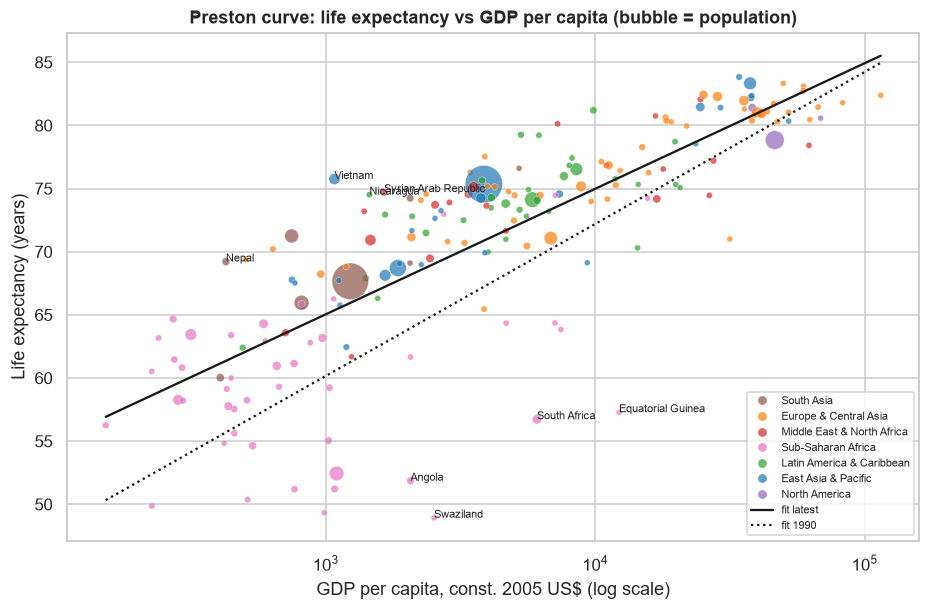

Largest over-performers (+) and under-performers (−) vs income-predicted life expectancy:


,ShortName,Region,gdp_pc,life_exp,resid
CountryCode,,,,,
VNM,Vietnam,East Asia & Pacific,"1,077.91",75.76,10.39
NPL,Nepal,South Asia,426.41,69.22,7.86
NIC,Nicaragua,Latin America & Caribbean,"1,453.81",74.51,7.86
SYR,Syrian Arab Republic,Middle East & North Africa,"1,648.81",74.72,7.52
BGD,Bangladesh,South Asia,747.37,71.25,7.46
SWZ,Swaziland,Sub-Saharan Africa,"2,526.46",48.94,-20.10
GNQ,Equatorial Guinea,Sub-Saharan Africa,"12,271.91",57.29,-18.57
AGO,Angola,Sub-Saharan Africa,"2,063.92",51.87,-16.30
ZAF,South Africa,Sub-Saharan Africa,"6,086.45",56.74,-16.10


In [26]:
pre = snapshot[["gdp_pc", "life_exp", "Region", "ShortName", "population"]].dropna()
pre["log_gdp"] = np.log10(pre.gdp_pc)
fit = stats.linregress(pre.log_gdp, pre.life_exp)
print(f"Latest: life_exp = {fit.intercept:.1f} + {fit.slope:.1f}·log10(GDPpc)   R²={fit.rvalue**2:.2f}  n={len(pre)}")

p90 = panel.xs(1990, level="Year")[["gdp_pc", "life_exp"]].dropna()
fit90 = stats.linregress(np.log10(p90.gdp_pc), p90.life_exp)
print(f"1990:   life_exp = {fit90.intercept:.1f} + {fit90.slope:.1f}·log10(GDPpc)   R²={fit90.rvalue**2:.2f}  n={len(p90)}")
at = np.log10(1000)
print(f"Predicted life expectancy at US$1,000: {fit90.intercept+fit90.slope*at:.1f} (1990) vs {fit.intercept+fit.slope*at:.1f} (latest)")

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=pre, x="gdp_pc", y="life_exp", hue="Region", size="population", sizes=(15, 600),
                palette=REGION_COLORS, alpha=.7, ax=ax, legend="brief")
xs = np.logspace(pre.log_gdp.min(), pre.log_gdp.max(), 50)
ax.plot(xs, fit.intercept + fit.slope * np.log10(xs), "k-", lw=1.5, label="fit latest")
ax.plot(xs, fit90.intercept + fit90.slope * np.log10(xs), "k:", lw=1.5, label="fit 1990")
ax.set_xscale("log")
ax.set(title="Preston curve: life expectancy vs GDP per capita (bubble = population)",
       xlabel="GDP per capita, const. 2005 US$ (log scale)", ylabel="Life expectancy (years)")
handles, labels = ax.get_legend_handles_labels()
keep = [i for i, l in enumerate(labels) if l in REGION_COLORS or l.startswith("fit")]
ax.legend([handles[i] for i in keep], [labels[i] for i in keep], fontsize=7, loc="lower right")
pre["resid"] = pre.life_exp - (fit.intercept + fit.slope * pre.log_gdp)
for _, r in pd.concat([pre.nlargest(4, "resid"), pre.nsmallest(4, "resid")]).iterrows():
    ax.annotate(r.ShortName, (r.gdp_pc, r.life_exp), fontsize=7)
save(fig, "17_preston_curve")
plt.show()

print("Largest over-performers (+) and under-performers (−) vs income-predicted life expectancy:")
pd.concat([pre.nlargest(5, "resid"), pre.nsmallest(5, "resid")])[["ShortName", "Region", "gdp_pc", "life_exp", "resid"]]

> **Preston curve findings.** Each 10-fold increase in GDP per capita goes with about **+10 years of life expectancy** (R² = 0.65), confirming the log-linear Preston relationship. The curve **shifted up over time**: at US$1,000 per head, predicted life expectancy rose from 60.2 (1990) to 65.0 years (latest). Countries now get more health for the same income, thanks to cheaper vaccines, oral rehydration, bed nets and antiretrovirals. Income explains about two-thirds of the variation. The residuals are informative:
> * **Over-performers**: Vietnam (+10.4 years above prediction), Nepal, Nicaragua, Syria (pre-war data) and Bangladesh. All invested heavily in primary healthcare, immunisation and female education.
> * **Under-performers**: Swaziland (−20 years), Lesotho, South Africa and Angola (HIV/AIDS), and Equatorial Guinea and Angola (oil wealth that did not translate into public health).

### 8.3 Predictive model for life expectancy (with cross-validation)
Can a handful of socio-economic indicators predict life expectancy *out of sample*? We compare:

1. **Baseline**: log GDP per capita only (linear).
2. **Multivariate linear regression**: income + water, urbanisation, education, fertility, health spending, electricity.
3. **Random forest**: same features, captures non-linearities and interactions.

All models are evaluated with **5-fold cross-validation** (R² and mean absolute error in years). Mortality indicators are deliberately *excluded* as features since they are mechanically part of life expectancy.

In [27]:
FEATS = ["log_gdp", "safe_water", "urban", "enrol_secondary", "fertility", "health_exp", "electricity", "female_lfp"]
mdl = snapshot.assign(log_gdp=np.log10(snapshot.gdp_pc))[FEATS + ["life_exp", "Income"]].dropna(subset=["life_exp", "log_gdp"])
# Impute remaining feature gaps with the income-group median (strategy from §4.2).
for f in FEATS:
    mdl[f] = mdl[f].fillna(mdl.groupby("Income", observed=True)[f].transform("median"))
mdl = mdl.dropna()
X, y = mdl[FEATS], mdl["life_exp"]
print(f"modelling sample: {len(mdl)} countries")

cv = KFold(5, shuffle=True, random_state=SEED)
models = {
    "Baseline: log GDP only": (make_pipeline(StandardScaler(), LinearRegression()), ["log_gdp"]),
    "Multivariate linear":    (make_pipeline(StandardScaler(), LinearRegression()), FEATS),
    "Random forest":          (RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED), FEATS),
}
results, preds = [], {}
for name, (m, cols) in models.items():
    p = cross_val_predict(m, X[cols], y, cv=cv)
    preds[name] = p
    results.append({"model": name, "CV R²": r2_score(y, p), "CV MAE (years)": mean_absolute_error(y, p)})
results = pd.DataFrame(results).set_index("model")
results

modelling sample: 192 countries


,CV R²,CV MAE (years)
model,,
Baseline: log GDP only,0.64,3.58
Multivariate linear,0.76,2.89
Random forest,0.76,2.81


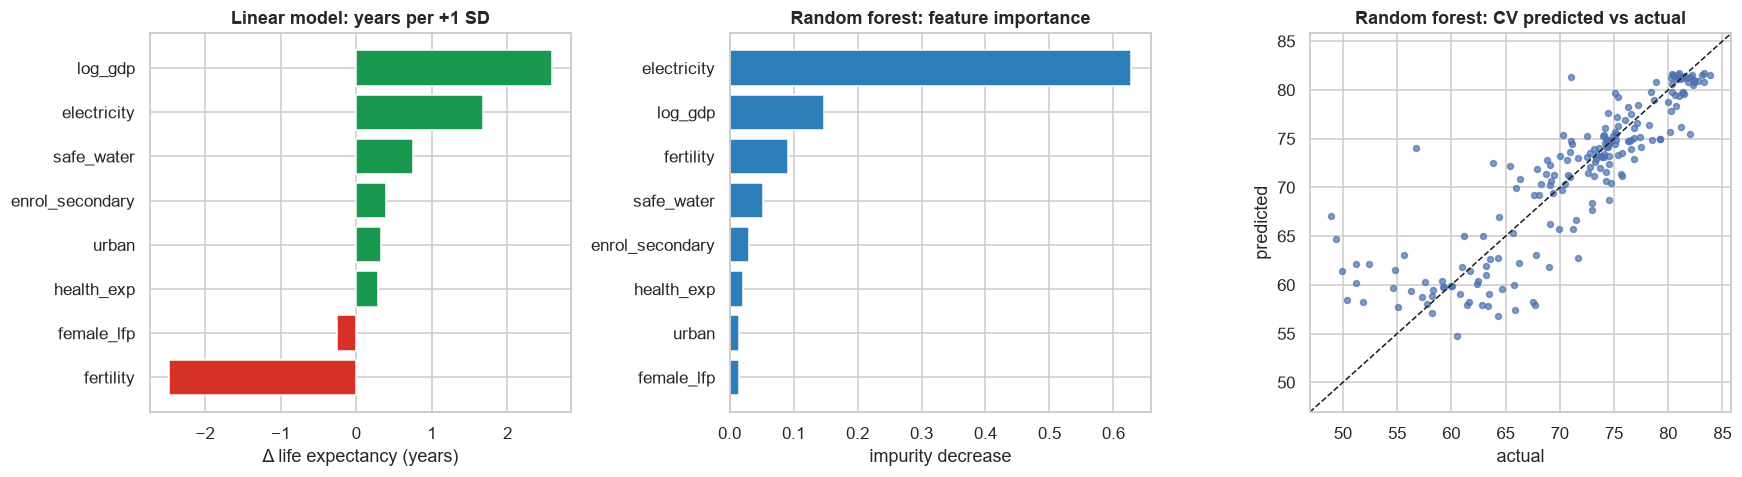

In [28]:
# Interpretation: standardised coefficients of the linear model (effect of +1 SD) and RF importances.
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
coef = pd.Series(lin[-1].coef_, index=FEATS).sort_values()
rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].barh(coef.index, coef.values, color=np.where(coef > 0, "#1a9850", "#d73027"))
axes[0].set(title="Linear model: years per +1 SD", xlabel="Δ life expectancy (years)")
axes[1].barh(imp.index, imp.values, color="#2c7fb8")
axes[1].set(title="Random forest: feature importance", xlabel="impurity decrease")
best = results["CV R²"].idxmax()
axes[2].scatter(y, preds[best], s=15, alpha=.7)
lims = [y.min() - 2, y.max() + 2]
axes[2].plot(lims, lims, "k--", lw=1)
axes[2].set(title=f"{best}: CV predicted vs actual", xlabel="actual", ylabel="predicted", xlim=lims, ylim=lims)
fig.tight_layout()
save(fig, "18_model_life_exp")
plt.show()

> **Model evaluation.** On unseen countries (5-fold CV), log GDP alone explains **64 %** of life-expectancy variance (MAE 3.6 years). Adding water access, urbanisation, schooling, fertility, health spending, electricity and female labour participation lifts this to **R² 0.76, MAE 2.9 years**. The random forest is no better than the linear model (R² 0.76, MAE 2.8). The relationship is close to linear once income is logged, so the simpler, interpretable linear model is preferred. In the linear model, fertility, electricity access and log income carry the largest weights. These are collinear "development" markers, so coefficients should be read as associations, not causal effects. The ~24 % unexplained variance is largely the HIV/AIDS-affected and resource-rich outliers above.

### 8.4 Environmental Kuznets curve: does CO₂ fall once countries get rich?
The EKC hypothesis says pollution first rises then falls with income (inverted U). We fit CO₂ per capita (log) on log income and its square across countries.

quadratic coef on log² income = -0.397; R² linear = 0.73, quadratic = 0.81
implied turning point: US$51,046 per capita;  countries above it: 9 of 192


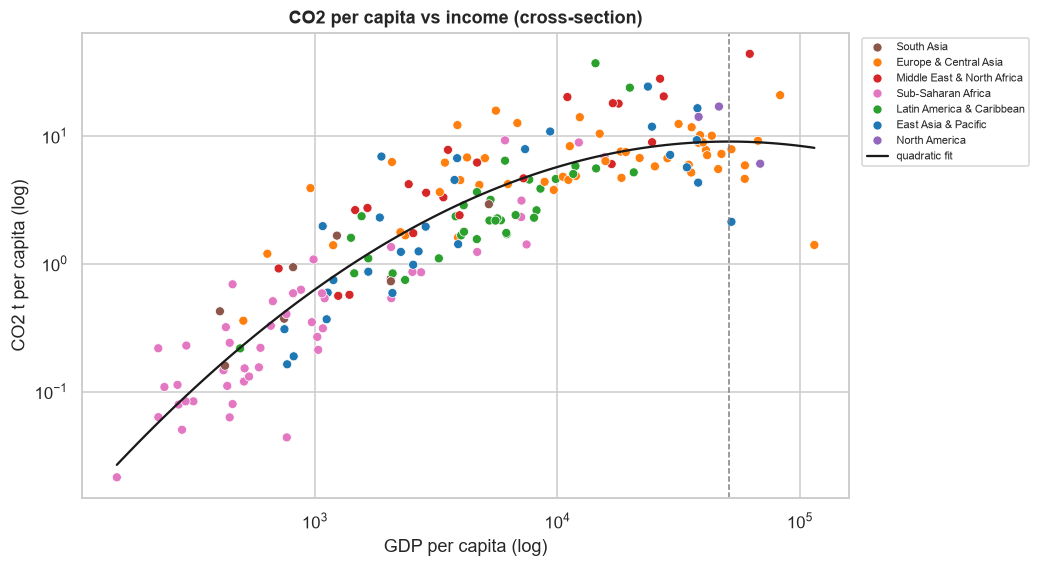

High-income countries with lower CO2 pc in 2011 than 1990: 26 of 56


In [29]:
ek = snapshot[["gdp_pc", "co2_pc", "Region", "ShortName"]].dropna().query("co2_pc > 0")
ek["x"], ek["y"] = np.log10(ek.gdp_pc), np.log10(ek.co2_pc)
b2, b1, b0 = np.polyfit(ek.x, ek.y, 2)
r2_quad = r2_score(ek.y, np.polyval([b2, b1, b0], ek.x))
r2_lin = stats.linregress(ek.x, ek.y).rvalue ** 2
turn = 10 ** (-b1 / (2 * b2)) if b2 < 0 else np.nan
print(f"quadratic coef on log² income = {b2:.3f}; R² linear = {r2_lin:.2f}, quadratic = {r2_quad:.2f}")
print(f"implied turning point: US${turn:,.0f} per capita;  countries above it: {(ek.gdp_pc > turn).sum()} of {len(ek)}")

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=ek, x="gdp_pc", y="co2_pc", hue="Region", palette=REGION_COLORS, ax=ax, s=35)
xs = np.linspace(ek.x.min(), ek.x.max(), 100)
ax.plot(10 ** xs, 10 ** np.polyval([b2, b1, b0], xs), "k-", lw=1.5, label="quadratic fit")
if np.isfinite(turn):
    ax.axvline(turn, c="grey", ls="--", lw=1)
ax.set(xscale="log", yscale="log", title="CO2 per capita vs income (cross-section)",
       xlabel="GDP per capita (log)", ylabel="CO2 t per capita (log)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "19_ekc")
plt.show()

# Within-country check for rich economies: change in CO2 pc 1990 -> 2011 in high-income countries.
hi = panel[panel.Income == "High income"]["co2_pc"].unstack("Year")[[1990, 2011]].dropna()
print(f"High-income countries with lower CO2 pc in 2011 than 1990: {(hi[2011] < hi[1990]).sum()} of {len(hi)}")

> **EKC findings.** The quadratic term is negative and improves fit (R² 0.73 → 0.81), so the cross-section has an inverted-U *shape*. But the implied turning point is about **US$51,000 per capita**, and only 9 of 192 countries are above it. In practice, emissions rise with income for almost every country. Within rich countries the evidence is mixed: only **26 of 56 high-income countries emitted less CO₂ per head in 2011 than in 1990**. Decoupling is possible but not automatic. Note that territorial CO₂ ignores emissions embodied in imports, which flatters rich importers.

### 8.5 Clustering: data-driven development profiles
World Bank income groups use one variable (GNI per capita). Here we let **K-means** group countries on **many** standardised indicators, and check:

* how many clusters the data support (silhouette score for k = 2…8),
* what each cluster looks like (profile table),
* how clusters line up with income groups (cross-tab),
* a 2-D **PCA** projection for visual sanity checking.

Skewed variables are log-transformed first; remaining gaps are filled with income-group medians.

clustering sample: 192 countries × 15 indicators (2.5% cells imputed)


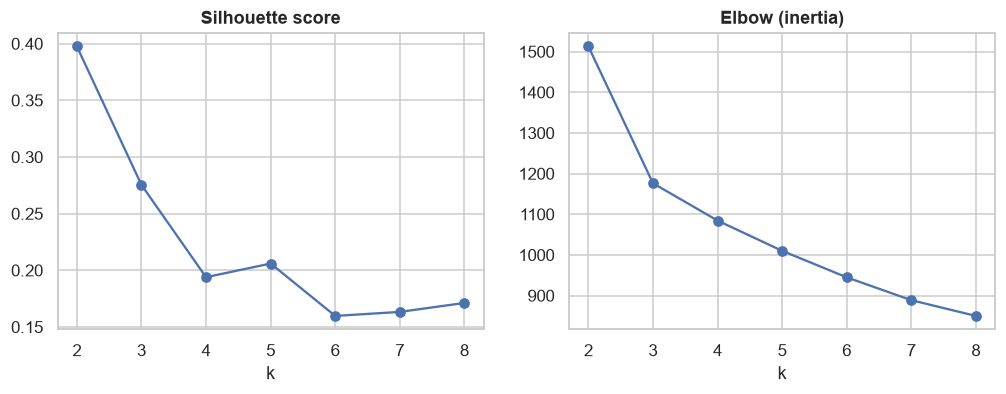

{2: np.float64(0.398), 3: np.float64(0.275), 4: np.float64(0.194), 5: np.float64(0.206), 6: np.float64(0.16), 7: np.float64(0.163), 8: np.float64(0.171)}


In [30]:
CL_VARS = ["gdp_pc", "life_exp", "u5_mort", "fertility", "urban", "age65", "enrol_secondary",
           "internet", "mobile", "electricity", "co2_pc", "energy_pc", "safe_water", "forest", "trade_open"]
LOG_VARS = ["gdp_pc", "u5_mort", "co2_pc", "energy_pc", "trade_open"]
cl = snapshot[["ShortName", "Region", "Income"] + CL_VARS].copy()
cl = cl[cl[CL_VARS].notna().mean(axis=1) >= 0.7]          # need ≥70% of variables observed
Xc = cl[CL_VARS].copy()
Xc[LOG_VARS] = np.log10(Xc[LOG_VARS].clip(lower=1e-2))
for v in CL_VARS:
    Xc[v] = Xc[v].fillna(Xc.groupby(cl["Income"], observed=True)[v].transform("median")).fillna(Xc[v].median())
Z = StandardScaler().fit_transform(Xc)
print(f"clustering sample: {len(cl)} countries × {len(CL_VARS)} indicators "
      f"({snapshot[CL_VARS].loc[cl.index].isna().mean().mean():.1%} cells imputed)")

ks = range(2, 9)
sil = [silhouette_score(Z, KMeans(k, n_init=20, random_state=SEED).fit_predict(Z)) for k in ks]
inertia = [KMeans(k, n_init=20, random_state=SEED).fit(Z).inertia_ for k in ks]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), sil, "o-"); axes[0].set(title="Silhouette score", xlabel="k")
axes[1].plot(list(ks), inertia, "o-"); axes[1].set(title="Elbow (inertia)", xlabel="k")
save(fig, "20_cluster_k")
plt.show()
print(dict(zip(ks, np.round(sil, 3))))

In [31]:
# k=4 gives interpretable groups comparable to the 4 income tiers; silhouette values are printed above for transparency.
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(Z)
# Relabel clusters so 0 = least developed ... 3 = most developed (ordered by median GDP pc).
order = cl.assign(c=km.labels_).groupby("c")["gdp_pc"].median().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
cl["cluster"] = pd.Series(km.labels_, index=cl.index).map(relabel)

profile = cl.groupby("cluster")[CL_VARS].median()
profile.insert(0, "n_countries", cl["cluster"].value_counts().sort_index())
display(profile.T.style.format("{:,.1f}").background_gradient(cmap="RdYlGn", axis=1)
        .set_caption("Cluster profiles (medians)"))
display(pd.crosstab(cl["cluster"], cl["Income"], margins=True).rename_axis(index="cluster", columns="WB income group"))
for c in range(K):
    print(f"Cluster {c}: ", ", ".join(cl[cl.cluster == c].sort_values("gdp_pc", ascending=False).ShortName.head(12)))

cluster,0,1,2,3
n_countries,45.0,38.0,59.0,50.0
gdp_pc,562.0,"1,655.2","5,305.7","27,959.5"
life_exp,59.3,69.4,74.3,80.6
u5_mort,75.9,31.8,14.6,4.2
fertility,4.9,3.0,2.0,1.6
urban,34.5,44.3,66.1,81.5
age65,3.0,4.7,7.4,16.0
enrol_secondary,40.4,80.0,93.0,105.5
internet,7.1,20.1,50.3,81.5
mobile,67.3,82.3,126.5,123.0


WB income group,Low income,Lower middle income,Upper middle income,High income,All
cluster,,,,,
0,27,16,1,1,45
1,3,27,8,0,38
2,0,7,40,12,59
3,0,0,2,48,50
All,30,50,51,61,192


Cluster 0:  Equatorial Guinea, Swaziland, Congo, Angola, Papua New Guinea, Kiribati, Solomon Islands, Nigeria, Côte d'Ivoire, Zambia, Cameroon, Lesotho
Cluster 1:  Botswana, Namibia, Belize, Fiji, Marshall Islands, Cabo Verde, Samoa, Tonga, Iraq, Guatemala, Micronesia, Paraguay
Cluster 2:  The Bahamas, Saudi Arabia, Seychelles, Barbados, Trinidad and Tobago, Antigua and Barbuda, St. Kitts and Nevis, Oman, Palau, Turkey, Mexico, Panama
Cluster 3:  Luxembourg, Bermuda, Norway, Qatar, Iceland, Switzerland, Macao SAR, China, Ireland, Denmark, United States, Sweden, Netherlands


explained variance: [0.635 0.073] → total 0.708


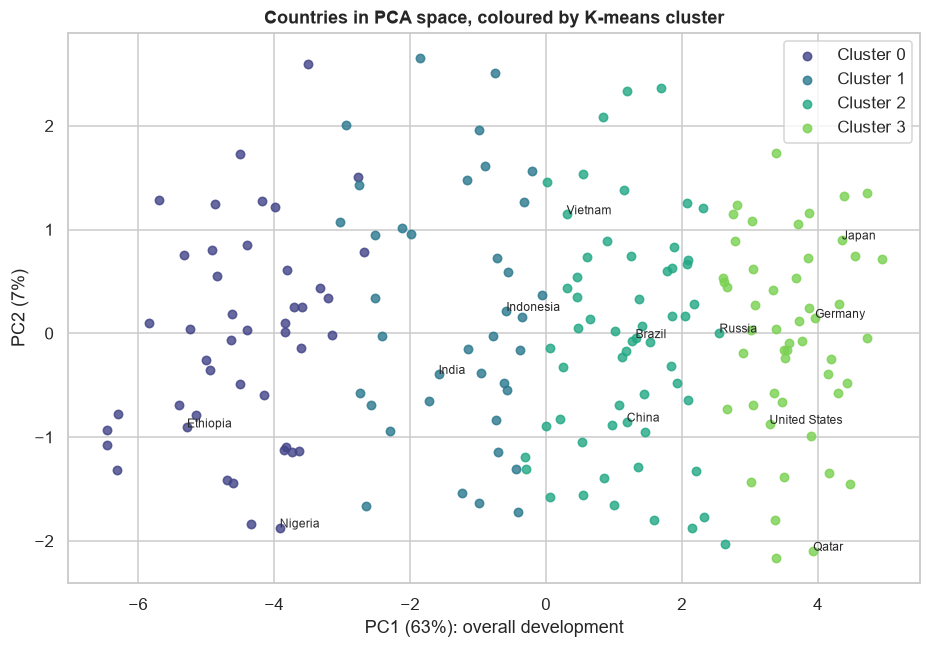

,PC1,PC2
u5_mort,-0.31,-0.05
fertility,-0.28,-0.09
forest,0.01,0.88
trade_open,0.10,0.33
mobile,0.21,-0.11
urban,0.24,-0.15
age65,0.25,0.16
safe_water,0.26,0.11
energy_pc,0.27,-0.17
electricity,0.28,-0.09


In [32]:
pca = PCA(2, random_state=SEED).fit(Z)
pcs = pca.transform(Z)
# PCA signs are arbitrary: orient PC1 so that higher = richer.
if pca.components_[0, CL_VARS.index("gdp_pc")] < 0:
    pca.components_[0] *= -1; pcs[:, 0] *= -1
print("explained variance:", np.round(pca.explained_variance_ratio_, 3), "→ total", round(pca.explained_variance_ratio_.sum(), 3))
loadings = pd.DataFrame(pca.components_.T, index=CL_VARS, columns=["PC1", "PC2"]).round(2)

CL_NAMES = {0: "C0", 1: "C1", 2: "C2", 3: "C3"}
fig, ax = plt.subplots(figsize=(10, 6.5))
pal = sns.color_palette("viridis", K)
for c in range(K):
    m = cl.cluster.values == c
    ax.scatter(pcs[m, 0], pcs[m, 1], s=30, color=pal[c], label=f"Cluster {c}", alpha=.8)
for code_ in ["USA", "CHN", "VNM", "IND", "NGA", "BRA", "DEU", "JPN", "QAT", "ETH", "RUS", "IDN"]:
    if code_ in cl.index:
        i = cl.index.get_loc(code_)
        ax.annotate(cl.loc[code_, "ShortName"], pcs[i], fontsize=8)
ax.set(title="Countries in PCA space, coloured by K-means cluster",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%}): overall development",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend()
save(fig, "21_pca_clusters")
plt.show()
loadings.sort_values("PC1")

In [33]:
# Cluster membership is saved for reuse (e.g. dashboards).
cl[["ShortName", "Region", "Income", "cluster"]].to_csv(PROCESSED / "country_clusters.csv")
cl.loc[cl.index.intersection(list(PEERS)), ["ShortName", "Income", "cluster"]]

,ShortName,Income,cluster
CountryCode,,,
CHN,China,Upper middle income,2
IND,India,Lower middle income,1
IDN,Indonesia,Lower middle income,1
MYS,Malaysia,Upper middle income,2
PHL,Philippines,Lower middle income,1
THA,Thailand,Upper middle income,2
VNM,Vietnam,Lower middle income,2


> **Clustering findings.**
> * Silhouette scores favour **k = 2** (0.40, essentially "developed vs developing"), and the score drops steadily after that. **k = 4** (silhouette 0.19) is used for interpretability. The low silhouette is itself a finding: development is a *continuum*, not discrete classes. PCA agrees: **PC1 alone explains 63 %** of the variance across 15 indicators, loading on income, internet, schooling, life expectancy and CO₂ (positive) versus child mortality and fertility (negative). PC2 (7 %) mostly captures forest cover and trade openness.
> * **Profiles (medians):**
>
> | Cluster | n | GDP pc | Life exp. | U5 mort. | Fertility | Internet | Electricity | CO₂ t |
> |---|---|---|---|---|---|---|---|---|
> | 0: low development | 45 | $562 | 59.3 | 75.9 | 4.9 | 7 | 27 % | 0.2 |
> | 1: transition | 38 | $1,655 | 69.4 | 31.8 | 3.0 | 20 | 79 % | 1.0 |
> | 2: emerging | 59 | $5,306 | 74.3 | 14.6 | 2.0 | 50 | 100 % | 3.9 |
> | 3: advanced | 50 | $27,960 | 80.6 | 4.2 | 1.6 | 82 | 100 % | 7.5 |
> * Clusters agree with World Bank income groups for **74 %** of countries (142/192 on the diagonal). The disagreements are the interesting part. Cluster 0 is 38/45 Sub-Saharan African and includes oil-rich Equatorial Guinea and Angola, whose social indicators match low-income countries. Rich Gulf and Caribbean states (Saudi Arabia, Oman, Bahamas) fall into the "emerging" cluster despite high income. **Vietnam is classified "emerging" (cluster 2) alongside China, Thailand and Malaysia, although the World Bank listed it as lower-middle income**: its social development runs ahead of its income.

## 9. Conclusions

### 9.1 Key insights

1. **Half a century of broad social progress.** Life expectancy rose in every region, by up to 30 years in South Asia. The high- vs low-income gap shrank from 30 to 21 years, primary schooling became near-universal, and mobile phones spread to every income group within 15 years.
2. **Income has not converged.** Cross-country income inequality is essentially unchanged (Gini ≈ 0.67–0.70, top/bottom decile ratio ~80×). β-convergence is weak (p ≈ 0.05). Catch-up happened in specific countries (China, Vietnam, India, Lao PDR), not across the board.
3. **The demographic transition is the dividing line.** Most of the world has reached roughly replacement fertility. Sub-Saharan Africa (fertility ~4.8, −28 % since 1960) has not, and this shapes population growth, age structure and the low-development cluster.
4. **Income matters, but policy shifts the curve.** Log income explains about 65 % of life-expectancy differences, and the Preston curve moved up about 5 years at a given income since 1990. Countries like Vietnam, Bangladesh and Nepal live 7–10 years longer than their income predicts; HIV-affected and oil-dependent economies live 15–20 years less.
5. **Growth still means more CO₂.** CO₂ per capita is as tightly linked to income as health is (ρ = 0.86). The cross-section EKC turning point (~US$51k) lies beyond almost every country, and fewer than half of rich countries cut per-capita emissions between 1990 and 2011.
6. **Development is one main dimension, but income groups miss part of it.** PC1 captures 63 % of variation in 15 indicators. Data-driven clusters agree with income groups for 74 % of countries; the remaining 26 % identify countries whose social outcomes lead or lag their income.

### 9.2 Limitations
* **Data vintage:** the Kaggle extract ends in 2014–2015 (CO₂ in 2011) and uses older WB income groups and 2005 constant prices. Results describe 1960–2014, not today.
* **Missing data are not random:** poorer and conflict-affected countries report less, especially for surveys (poverty, literacy, Gini). Snapshot values come from different years within 2005–2014.
* **Cross-sectional associations ≠ causation:** correlations, the Preston curve and the EKC describe patterns across countries, not the effect of a policy within a country.
* **Unweighted country medians:** each country counts once (Tuvalu = China). This is appropriate for "the typical country" but not for "the typical person". Population-weighted world aggregates are shown where available.
* **Territorial CO₂** excludes emissions embodied in trade.

### 9.3 Possible extensions
* Refresh with the current WDI API (`wbgapi`) to extend the series to the 2020s and test whether the conclusions hold after COVID-19.
* Panel regressions with country fixed effects to study *within-country* changes (e.g. does health spending raise life expectancy over time?).
* Population-weighted inequality (between-person rather than between-country) and consumption-based CO₂.
* An interactive dashboard (e.g. Streamlit/Power BI) on top of the processed files in `data/processed/`.